In [ ]:
  !pip -q install torch

# Import Libraries
import pandas as pd
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/weatherHistory.csv")

print(df.head())
print(df.info())

                  Formatted Date        Summary Precip Type  Temperature (C)  \
0  2006-04-01 00:00:00.000 +0200  Partly Cloudy        rain         9.472222   
1  2006-04-01 01:00:00.000 +0200  Partly Cloudy        rain         9.355556   
2  2006-04-01 02:00:00.000 +0200  Mostly Cloudy        rain         9.377778   
3  2006-04-01 03:00:00.000 +0200  Partly Cloudy        rain         8.288889   
4  2006-04-01 04:00:00.000 +0200  Mostly Cloudy        rain         8.755556   

   Apparent Temperature (C)  Humidity  Wind Speed (km/h)  \
0                  7.388889      0.89            14.1197   
1                  7.227778      0.86            14.2646   
2                  9.377778      0.89             3.9284   
3                  5.944444      0.83            14.1036   
4                  6.977778      0.83            11.0446   

   Wind Bearing (degrees)  Visibility (km)  Loud Cover  Pressure (millibars)  \
0                   251.0          15.8263         0.0               1015.13  

In [ ]:
# Remove missing values
df = df.dropna()

# Select useful numerical features
features = [
    "Temperature (C)",
    "Humidity",
    "Wind Speed (km/h)",
    "Wind Bearing (degrees)",
    "Visibility (km)",
    "Pressure (millibars)"
]

X = df[features]

# Target column
y = df["Summary"]

# Encode labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
# Convert to Tensor
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)

y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)


NameError: name 'df' is not defined

In [ ]:
class WeatherNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(6,64)
        self.fc2 = nn.Linear(64,32)
        self.fc3 = nn.Linear(32,len(label_encoder.classes_))

        self.relu = nn.ReLU()

    def forward(self,x):

        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)

        return x


model = WeatherNN()

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
epochs = 30

losses = []

for epoch in range(epochs):

    outputs = model(X_train)

    loss = criterion(outputs, y_train)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    losses.append(loss.item())

    print(f"Epoch {epoch+1}/{epochs} Loss = {loss.item():.4f}")


Epoch 1/30 Loss = 3.2979
Epoch 2/30 Loss = 3.2834
Epoch 3/30 Loss = 3.2690
Epoch 4/30 Loss = 3.2547
Epoch 5/30 Loss = 3.2405
Epoch 6/30 Loss = 3.2262
Epoch 7/30 Loss = 3.2117
Epoch 8/30 Loss = 3.1969
Epoch 9/30 Loss = 3.1819
Epoch 10/30 Loss = 3.1664
Epoch 11/30 Loss = 3.1504
Epoch 12/30 Loss = 3.1338
Epoch 13/30 Loss = 3.1165
Epoch 14/30 Loss = 3.0984
Epoch 15/30 Loss = 3.0795
Epoch 16/30 Loss = 3.0596
Epoch 17/30 Loss = 3.0388
Epoch 18/30 Loss = 3.0168
Epoch 19/30 Loss = 2.9937
Epoch 20/30 Loss = 2.9694
Epoch 21/30 Loss = 2.9437
Epoch 22/30 Loss = 2.9168
Epoch 23/30 Loss = 2.8886
Epoch 24/30 Loss = 2.8590
Epoch 25/30 Loss = 2.8280
Epoch 26/30 Loss = 2.7957
Epoch 27/30 Loss = 2.7620
Epoch 28/30 Loss = 2.7271
Epoch 29/30 Loss = 2.6909
Epoch 30/30 Loss = 2.6537


In [ ]:
with torch.no_grad():

    predictions = model(X_test)

    _, predicted = torch.max(predictions,1)

accuracy = accuracy_score(y_test,predicted)

print("\nAccuracy :",accuracy)

print("\nClassification Report\n")
print(classification_report(
    y_test,
    predicted,
    labels=np.arange(len(label_encoder.classes_)), # Add this line to specify all possible labels
    target_names=label_encoder.classes_
))


Accuracy : 0.22347300396080885

Classification Report

                                     precision    recall  f1-score   support

                             Breezy       0.00      0.00      0.00         9
                     Breezy and Dry       0.00      0.00      0.00         0
                   Breezy and Foggy       0.00      0.00      0.00         6
           Breezy and Mostly Cloudy       0.00      0.00      0.00        95
                Breezy and Overcast       0.00      0.00      0.00       108
           Breezy and Partly Cloudy       0.00      0.00      0.00        77
                              Clear       0.14      0.74      0.23      2161
Dangerously Windy and Partly Cloudy       0.00      0.00      0.00         0
                            Drizzle       0.00      0.00      0.00         8
                                Dry       0.00      0.00      0.00         7
              Dry and Mostly Cloudy       0.00      0.00      0.00         3
              Dry a

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/me

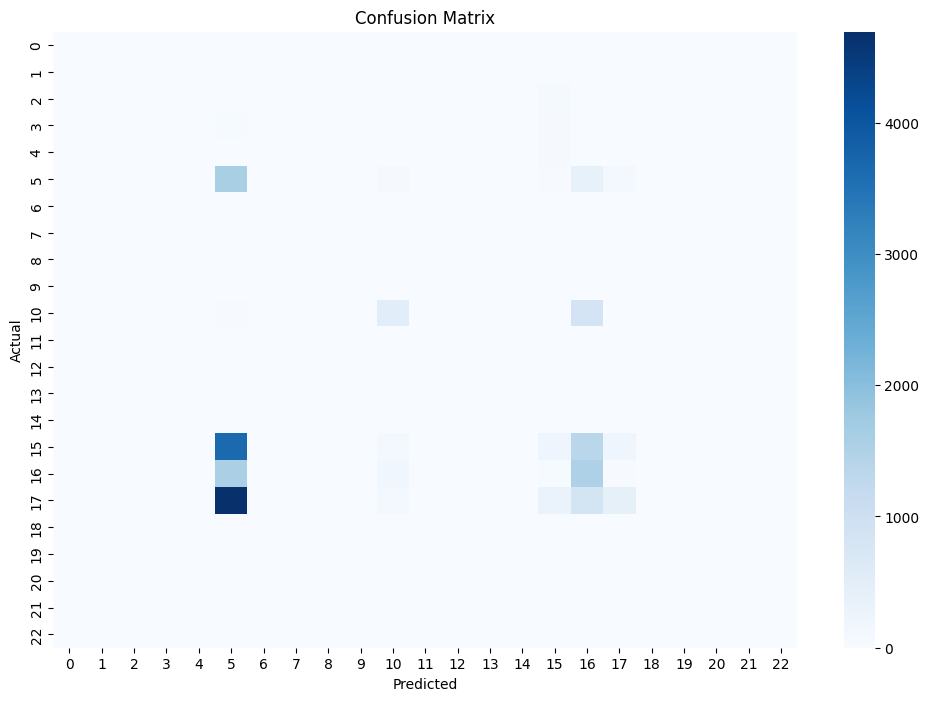

In [ ]:
cm = confusion_matrix(y_test,predicted)

plt.figure(figsize=(12,8))

sns.heatmap(
    cm,
    annot=False,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# LAB ASSIGNMENT-II

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 

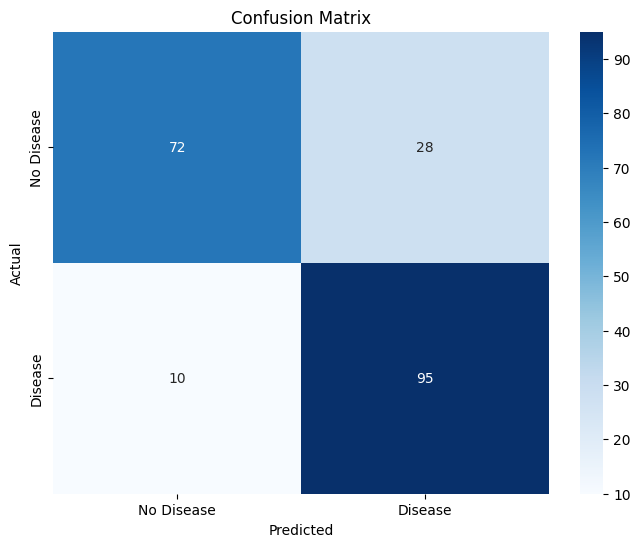

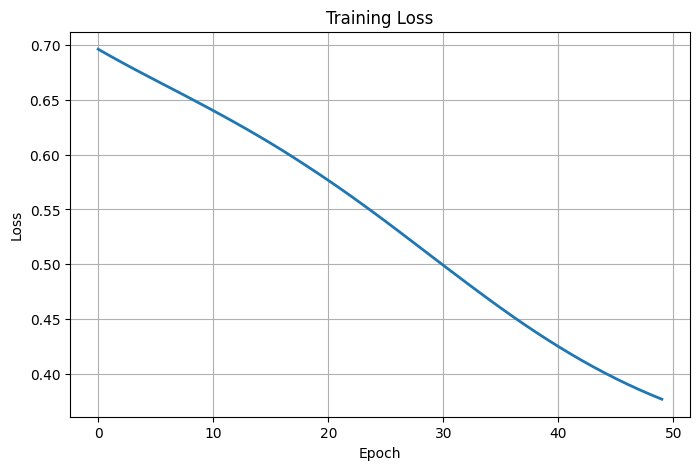

In [ ]:
!pip -q install torch

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/heart.csv")

print(df.head())
print(df.info())

df = df.dropna()

X = df.drop("target", axis=1)
y = df["target"]

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)

y_train = torch.FloatTensor(y_train.values).reshape(-1, 1)
y_test = torch.FloatTensor(y_test.values).reshape(-1, 1)

class HeartDiseaseNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(13, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)

        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.sigmoid(self.fc3(x))
        return x

model = HeartDiseaseNN()

criterion = nn.BCELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 50

losses = []

for epoch in range(epochs):

    outputs = model(X_train)

    loss = criterion(outputs, y_train)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    losses.append(loss.item())

    print(
        "Epoch",
        epoch + 1,
        "Loss =",
        loss.item()
    )

with torch.no_grad():

    outputs = model(X_test)

    predicted = (outputs >= 0.5).float()

accuracy = accuracy_score(
    y_test.numpy(),
    predicted.numpy()
)

print("Accuracy:", accuracy)

print(
    classification_report(
        y_test.numpy(),
        predicted.numpy(),
        target_names=["No Heart Disease", "Heart Disease"]
    )
)

cm = confusion_matrix(
    y_test.numpy(),
    predicted.numpy()
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    losses,
    linewidth=2
)

plt.title("Training Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.grid(True)

plt.show()

    Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  \
0  28395    610.291       208.178117       173.888747      1.197191   
1  28734    638.018       200.524796       182.734419      1.097356   
2  29380    624.110       212.826130       175.931143      1.209713   
3  30008    645.884       210.557999       182.516516      1.153638   
4  30140    620.134       201.847882       190.279279      1.060798   

   Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  roundness  \
0      0.549812       28715     190.141097  0.763923  0.988856   0.958027   
1      0.411785       29172     191.272750  0.783968  0.984986   0.887034   
2      0.562727       29690     193.410904  0.778113  0.989559   0.947849   
3      0.498616       30724     195.467062  0.782681  0.976696   0.903936   
4      0.333680       30417     195.896503  0.773098  0.990893   0.984877   

   Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  Class  
0     0.913358      0.007332  

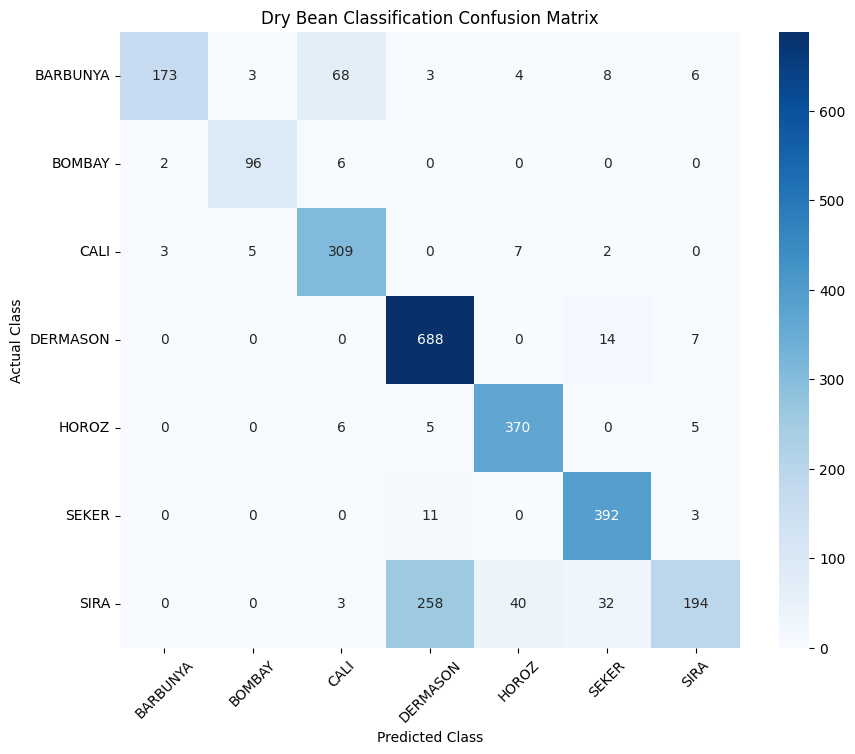

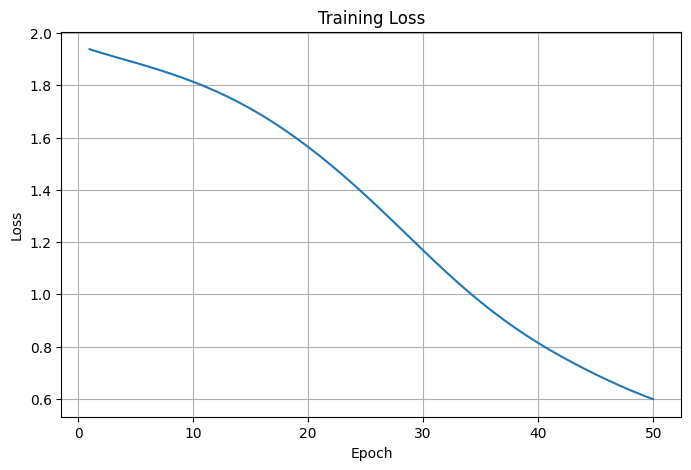

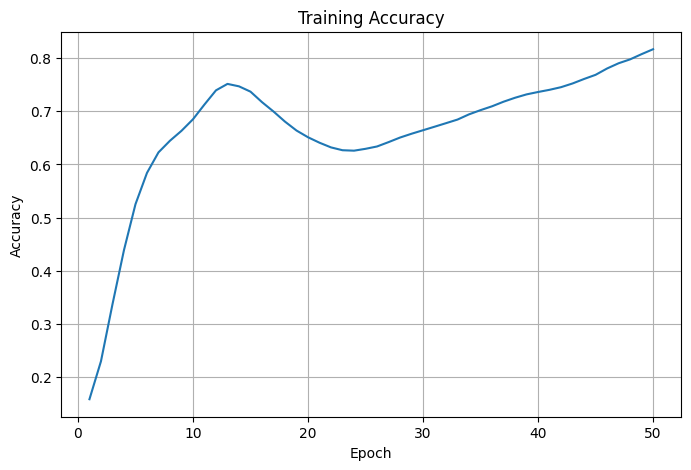

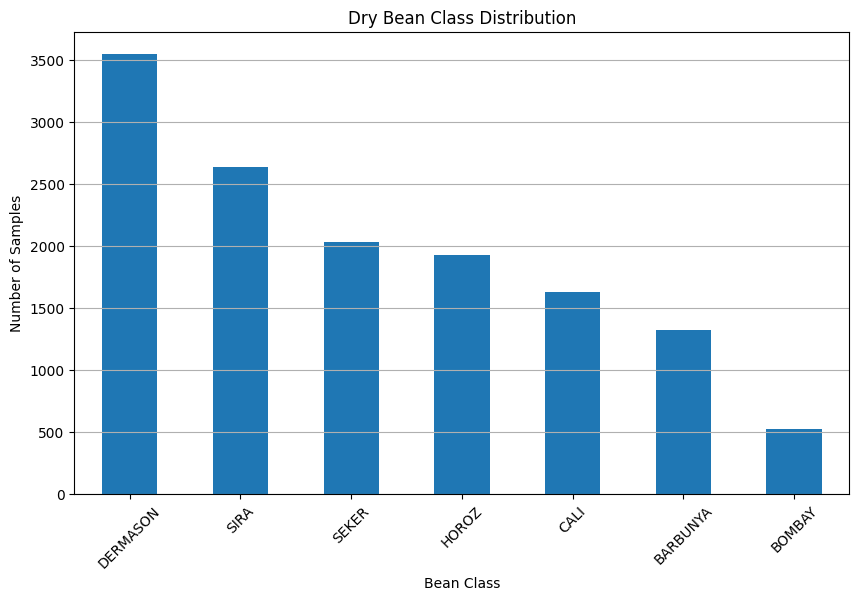

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/content/Dry_Bean_Dataset.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Dry_Beans_Dataset"
)

print(df.head())
print(df.shape)
print(df.info())

df = df.dropna()

X = df.drop("Class", axis=1)

y = df["Class"]

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

scaler = StandardScaler()

X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = torch.FloatTensor(X_train)

X_test = torch.FloatTensor(X_test)

y_train = torch.LongTensor(y_train)

y_test = torch.LongTensor(y_test)

class DryBeanNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(16, 128)

        self.fc2 = nn.Linear(128, 64)

        self.fc3 = nn.Linear(64, 32)

        self.fc4 = nn.Linear(
            32,
            len(label_encoder.classes_)
        )

        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.relu(self.fc1(x))

        x = self.relu(self.fc2(x))

        x = self.relu(self.fc3(x))

        x = self.fc4(x)

        return x

model = DryBeanNN()

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 50

losses = []

accuracies = []

for epoch in range(epochs):

    model.train()

    outputs = model(X_train)

    loss = criterion(
        outputs,
        y_train
    )

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    losses.append(loss.item())

    model.eval()

    with torch.no_grad():

        train_outputs = model(X_train)

        _, train_predicted = torch.max(
            train_outputs,
            1
        )

        train_accuracy = accuracy_score(
            y_train.numpy(),
            train_predicted.numpy()
        )

    accuracies.append(train_accuracy)

    print(
        "Epoch",
        epoch + 1,
        "Loss =",
        round(loss.item(), 4),
        "Accuracy =",
        round(train_accuracy, 4)
    )

model.eval()

with torch.no_grad():

    outputs = model(X_test)

    _, predicted = torch.max(
        outputs,
        1
    )

accuracy = accuracy_score(
    y_test.numpy(),
    predicted.numpy()
)

print("\nTest Accuracy:", accuracy)

print("\nClassification Report:")

print(
    classification_report(
        y_test.numpy(),
        predicted.numpy(),
        target_names=label_encoder.classes_
    )
)

cm = confusion_matrix(
    y_test.numpy(),
    predicted.numpy()
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(
    "Dry Bean Classification Confusion Matrix"
)

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.xticks(rotation=45)

plt.yticks(rotation=0)

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    losses
)

plt.title("Training Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.grid(True)

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    accuracies
)

plt.title("Training Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.grid(True)

plt.show()

class_counts = df["Class"].value_counts()

plt.figure(figsize=(10, 6))

class_counts.plot(
    kind="bar"
)

plt.title(
    "Dry Bean Class Distribution"
)

plt.xlabel("Bean Class")

plt.ylabel("Number of Samples")

plt.xticks(rotation=45)

plt.grid(axis="y")

plt.show()

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4        5   0  
1      9.8        5   1  
2      9

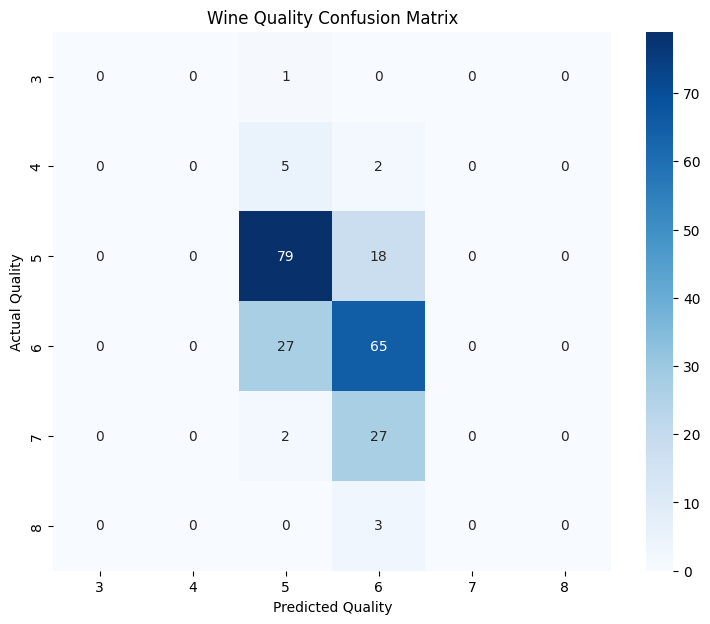

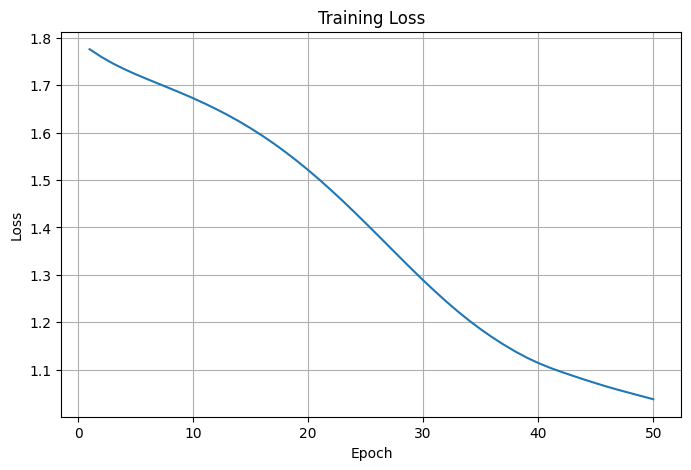

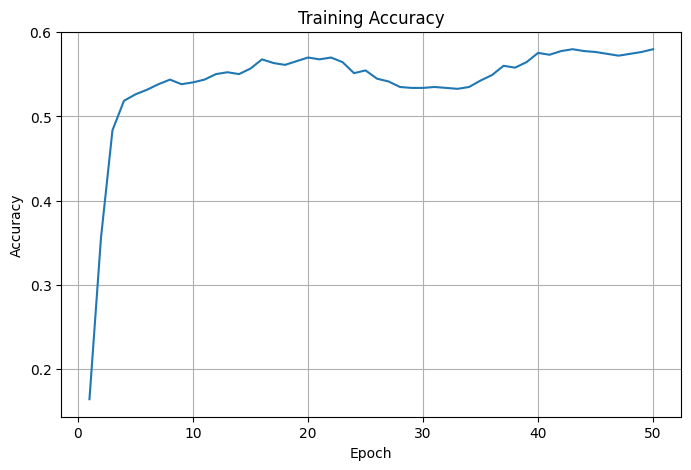

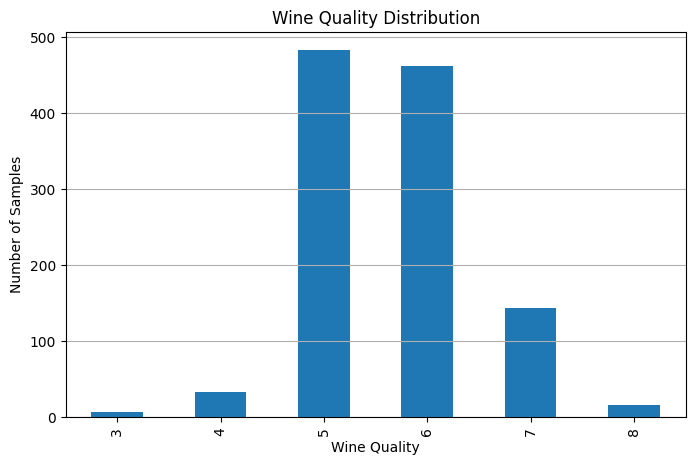

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/content/WineQT.csv"

df = pd.read_csv(file_path)

print(df.head())
print(df.shape)
print(df.info())

df = df.dropna()

X = df.drop(["quality", "Id"], axis=1)

y = df["quality"]

quality_values = sorted(y.unique())

quality_mapping = {
    value: index
    for index, value in enumerate(quality_values)
}

y = y.map(quality_mapping).values

scaler = StandardScaler()

X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = torch.FloatTensor(X_train)

X_test = torch.FloatTensor(X_test)

y_train = torch.LongTensor(y_train)

y_test = torch.LongTensor(y_test)

class WineQualityNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(X_train.shape[1], 128)

        self.fc2 = nn.Linear(128, 64)

        self.fc3 = nn.Linear(64, 32)

        self.fc4 = nn.Linear(
            32,
            len(quality_values)
        )

        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.relu(self.fc1(x))

        x = self.relu(self.fc2(x))

        x = self.relu(self.fc3(x))

        x = self.fc4(x)

        return x

model = WineQualityNN()

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 50

losses = []

accuracies = []

for epoch in range(epochs):

    model.train()

    outputs = model(X_train)

    loss = criterion(
        outputs,
        y_train
    )

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    losses.append(loss.item())

    model.eval()

    with torch.no_grad():

        train_outputs = model(X_train)

        _, train_predicted = torch.max(
            train_outputs,
            1
        )

        train_accuracy = accuracy_score(
            y_train.numpy(),
            train_predicted.numpy()
        )

    accuracies.append(train_accuracy)

    print(
        "Epoch",
        epoch + 1,
        "Loss =",
        round(loss.item(), 4),
        "Accuracy =",
        round(train_accuracy, 4)
    )

model.eval()

with torch.no_grad():

    outputs = model(X_test)

    _, predicted = torch.max(
        outputs,
        1
    )

accuracy = accuracy_score(
    y_test.numpy(),
    predicted.numpy()
)

print("\nTest Accuracy:", accuracy)

print("\nClassification Report:")

print(
    classification_report(
        y_test.numpy(),
        predicted.numpy(),
        labels=range(len(quality_values)),
        target_names=[
            str(value)
            for value in quality_values
        ],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test.numpy(),
    predicted.numpy()
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=quality_values,
    yticklabels=quality_values
)

plt.title("Wine Quality Confusion Matrix")

plt.xlabel("Predicted Quality")

plt.ylabel("Actual Quality")

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    losses
)

plt.title("Training Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.grid(True)

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    accuracies
)

plt.title("Training Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.grid(True)

plt.show()

plt.figure(figsize=(8, 5))

df["quality"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Wine Quality Distribution")

plt.xlabel("Wine Quality")

plt.ylabel("Number of Samples")

plt.grid(axis="y")

plt.show()

Using device: cpu


100%|██████████| 170M/170M [51:45<00:00, 54.9kB/s]


Training samples: 50000
Testing samples: 10000
Number of classes: 10


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


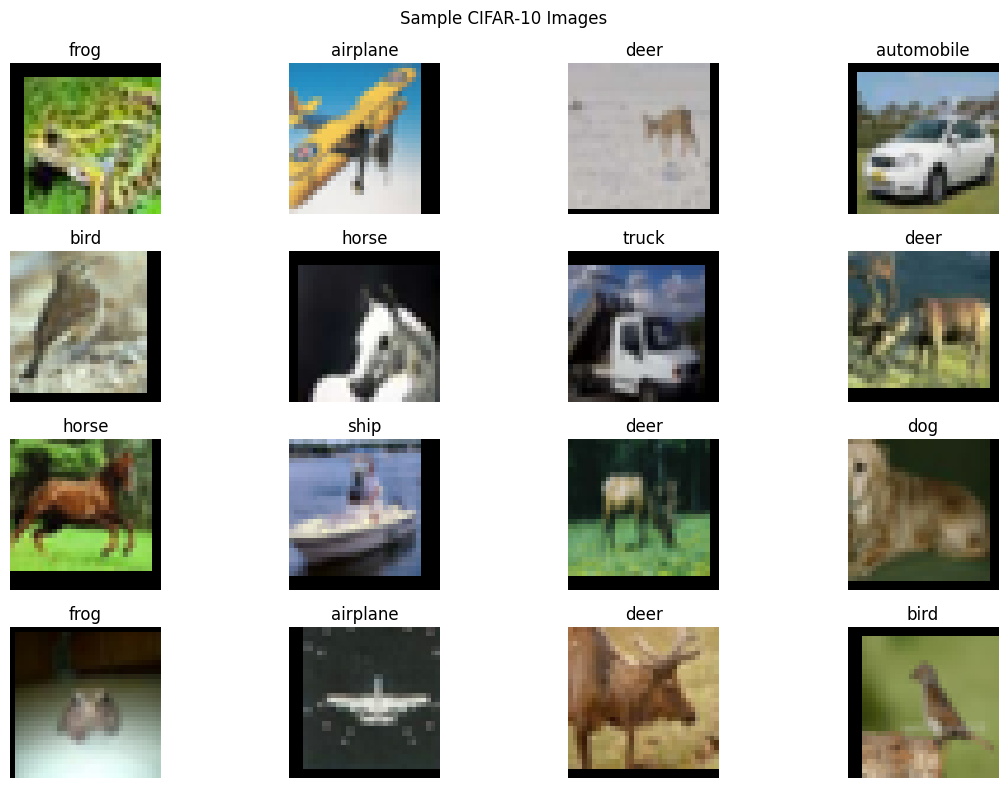

CIFAR10CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.25, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout(p=0.25, inpl

In [ ]:
# ============================================================
# CIFAR-10 IMAGE CLASSIFICATION USING PYTORCH
# ============================================================

# -----------------------------
# 1. IMPORT LIBRARIES
# -----------------------------
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)


# ============================================================
# 2. LOAD AND PREPROCESS CIFAR-10 DATASET
# ============================================================

# CIFAR-10 mean and standard deviation
# Commonly used values for normalization
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# Training transformations
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Test transformations
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Download/load training dataset
train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

# Download/load test dataset
test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)

# Data loaders
batch_size = 128

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# CIFAR-10 class names
classes = (
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Number of classes:", len(classes))


# ============================================================
# 3. VISUALIZE SAMPLE IMAGES
# ============================================================

# Get one batch
images, labels = next(iter(train_loader))

# Function to denormalize images
def denormalize(image):
    image = image * torch.tensor(std).view(3, 1, 1)
    image = image + torch.tensor(mean).view(3, 1, 1)
    return image


# Display sample images
plt.figure(figsize=(12, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    img = denormalize(images[i])
    img = torch.clamp(img, 0, 1)

    plt.imshow(img.permute(1, 2, 0))
    plt.title(classes[labels[i]])
    plt.axis("off")

plt.suptitle("Sample CIFAR-10 Images")
plt.tight_layout()
plt.show()


# ============================================================
# 4. BUILD CNN MODEL
# ============================================================

class CIFAR10CNN(nn.Module):

    def __init__(self):
        super(CIFAR10CNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout(0.25),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout(0.25),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Create model
model = CIFAR10CNN().to(device)

print(model)


# ============================================================
# 5. LOSS FUNCTION AND OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Learning-rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)


# ============================================================
# 6. TRAINING FUNCTION
# ============================================================

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


# ============================================================
# 7. EVALUATION FUNCTION
# ============================================================

def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_predictions.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return (
        epoch_loss,
        epoch_accuracy,
        np.array(all_labels),
        np.array(all_predictions)
    )


# ============================================================
# 8. TRAIN THE MODEL
# ============================================================

num_epochs = 15

train_losses = []
train_accuracies = []

test_losses = []
test_accuracies = []

best_accuracy = 0.0

print("\nStarting training...\n")

for epoch in range(num_epochs):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    test_loss, test_accuracy, _, _ = evaluate(
        model,
        test_loader,
        criterion
    )

    scheduler.step(test_loss)

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

    # Save best model
    if test_accuracy > best_accuracy:

        best_accuracy = test_accuracy

        torch.save(
            model.state_dict(),
            "best_cifar10_model.pth"
        )

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

print("\nTraining completed.")
print(f"Best test accuracy: {best_accuracy:.2f}%")


# ============================================================
# 9. LOAD BEST MODEL
# ============================================================

model.load_state_dict(
    torch.load(
        "best_cifar10_model.pth",
        map_location=device
    )
)

model.eval()


# ============================================================
# 10. FINAL EVALUATION
# ============================================================

test_loss, test_accuracy, y_true, y_pred = evaluate(
    model,
    test_loader,
    criterion
)

print("\n==============================")
print("FINAL TEST RESULTS")
print("==============================")

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.2f}%")


# ============================================================
# 11. CLASSIFICATION REPORT
# ============================================================

print("\n==============================")
print("CLASSIFICATION REPORT")
print("==============================")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes,
        digits=4
    )
)


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()


# ============================================================
# 13. PLOT TRAINING AND TEST LOSS
# ============================================================

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    test_losses,
    marker="o",
    label="Test Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Test Loss")
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# 14. PLOT TRAINING AND TEST ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    test_accuracies,
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Test Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# 15. DISPLAY PREDICTIONS
# ============================================================

# Get a batch from test set
images, labels = next(iter(test_loader))

images_gpu = images.to(device)

with torch.no_grad():

    outputs = model(images_gpu)

    _, predictions = torch.max(outputs, 1)


# Display predictions
plt.figure(figsize=(12, 8))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    img = denormalize(images[i])
    img = torch.clamp(img, 0, 1)

    plt.imshow(img.permute(1, 2, 0))

    true_label = classes[labels[i]]
    predicted_label = classes[predictions[i].cpu()]

    if true_label == predicted_label:
        title = f"True: {true_label}\nPred: {predicted_label}"
    else:
        title = f"True: {true_label}\nPred: {predicted_label}"

    plt.title(title, fontsize=9)
    plt.axis("off")

plt.suptitle("CIFAR-10 Model Predictions")
plt.tight_layout()
plt.show()


# ============================================================
# 16. PER-CLASS ACCURACY
# ============================================================

print("\n==============================")
print("PER-CLASS ACCURACY")
print("==============================")

for i, class_name in enumerate(classes):

    class_mask = (y_true == i)

    class_correct = np.sum(
        y_pred[class_mask] == i
    )

    class_total = np.sum(class_mask)

    class_accuracy = (
        100 * class_correct / class_total
    )

    print(
        f"{class_name:12s}: "
        f"{class_accuracy:.2f}%"
    )


# ============================================================
# 17. FINAL CONCLUSION
# ============================================================

print("\n==============================")
print("CONCLUSION")
print("==============================")

print(f"""
The CNN was trained on the CIFAR-10 dataset using PyTorch.

The final test accuracy was {test_accuracy:.2f}%.

The training and test accuracy curves show how the model
learned throughout the training process, while the loss curves
show the reduction in classification error.

The confusion matrix and classification report provide a
class-wise evaluation using precision, recall and F1-score.

Classes with similar visual characteristics, such as cats and
dogs, may have more classification errors because their images
can have similar shapes and colors.

Overall, the CNN is capable of learning useful visual features
from CIFAR-10 images and performing multi-class image
classification successfully.
""")

Using device: cpu


100%|██████████| 26.4M/26.4M [00:01<00:00, 18.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 262kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.05MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.8MB/s]

Training samples: 60000
Testing samples: 10000
Number of classes: 10



/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


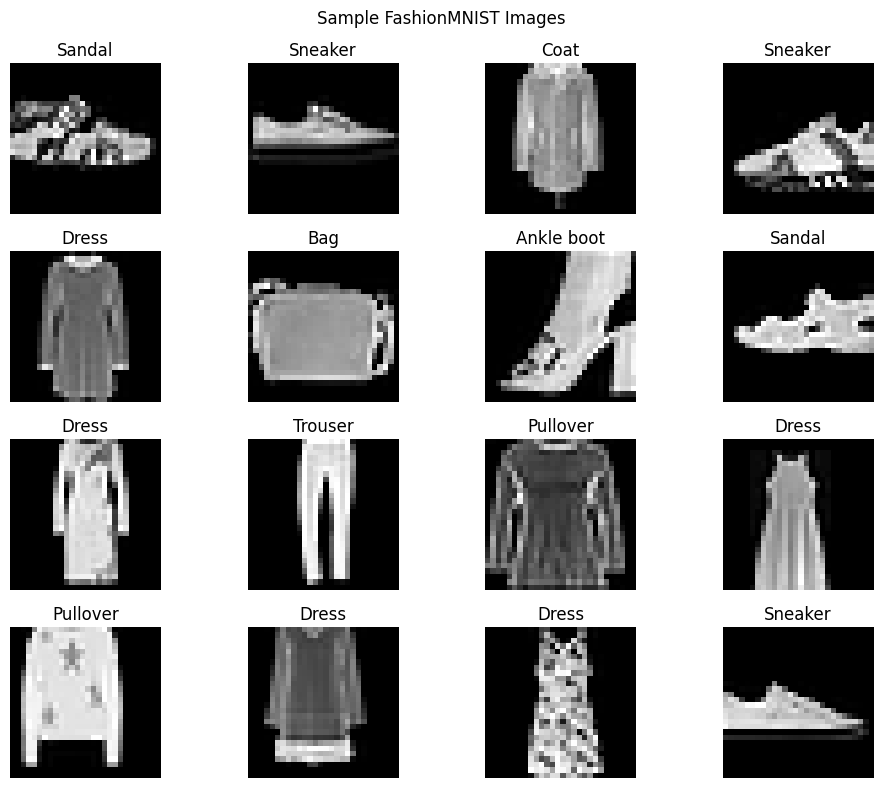

FashionMNISTCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.25, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout(p=0.25,

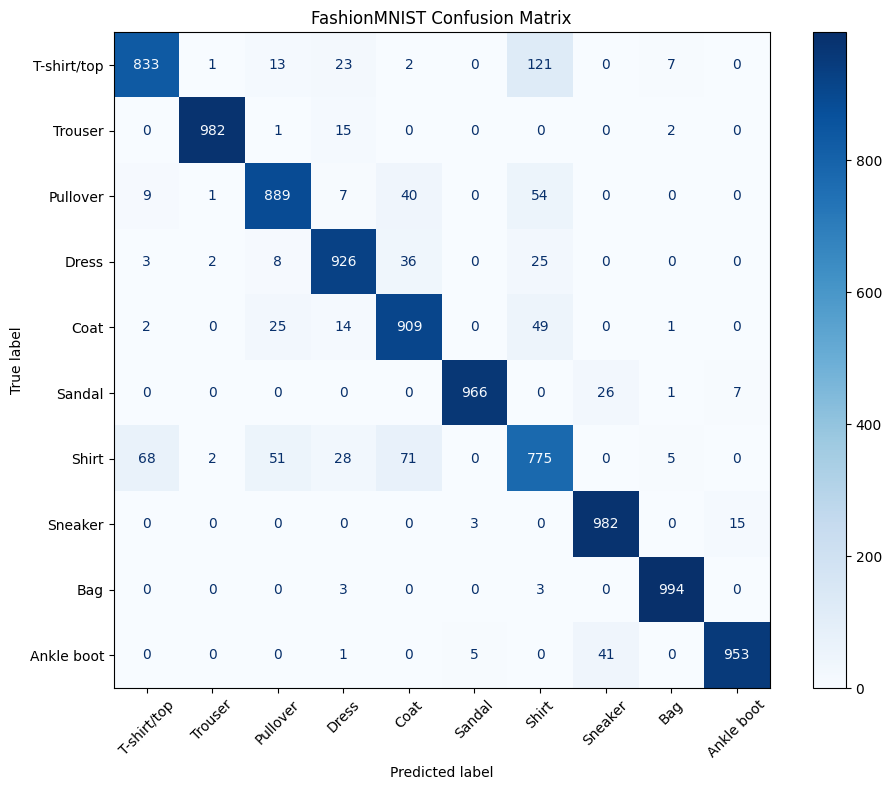

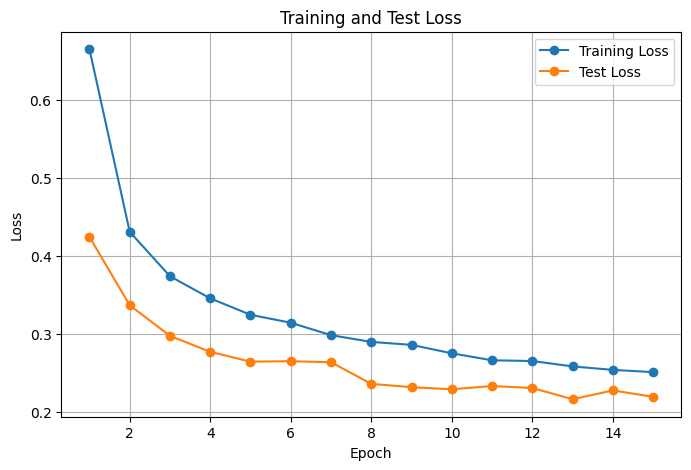

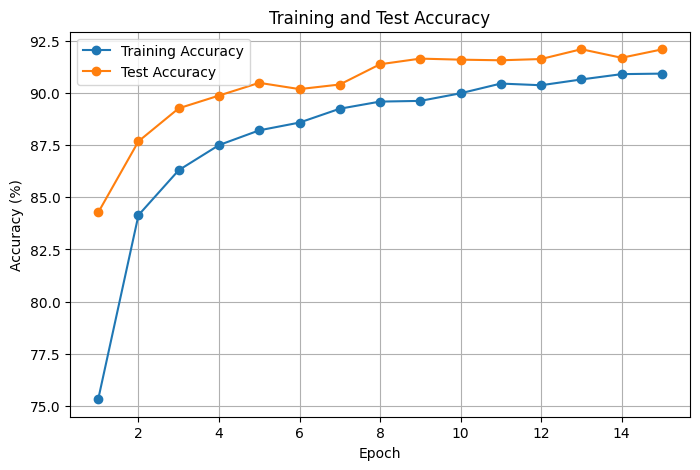

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


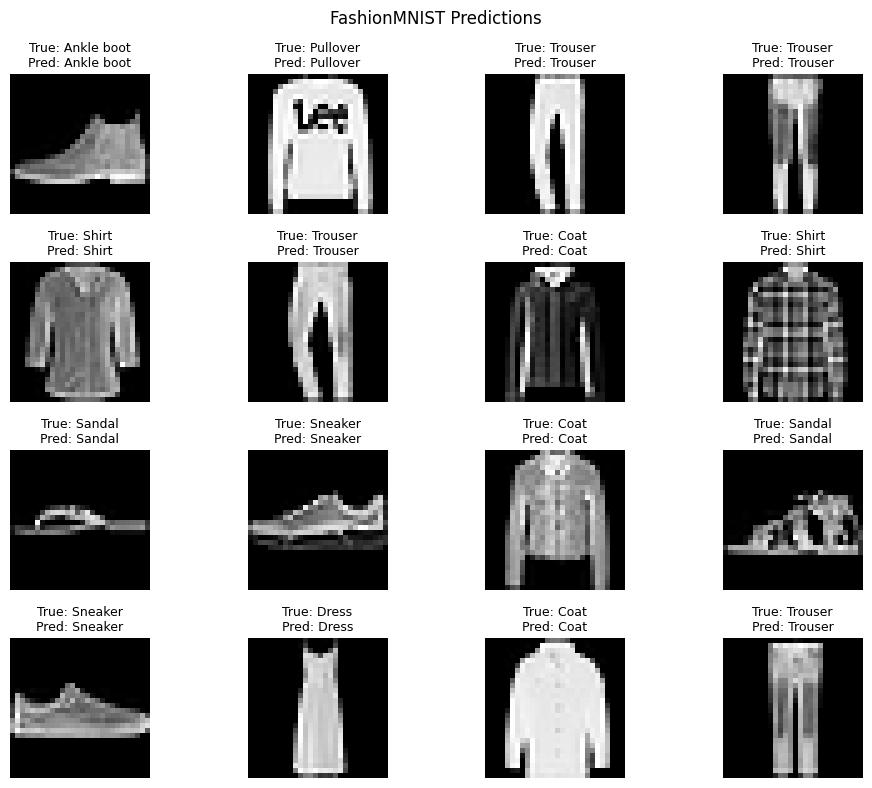


PER-CLASS ACCURACY
T-shirt/top    : 83.30%
Trouser        : 98.20%
Pullover       : 88.90%
Dress          : 92.60%
Coat           : 90.90%
Sandal         : 96.60%
Shirt          : 77.50%
Sneaker        : 98.20%
Bag            : 99.40%
Ankle boot     : 95.30%

Feature map shape: torch.Size([1, 128, 3, 3])


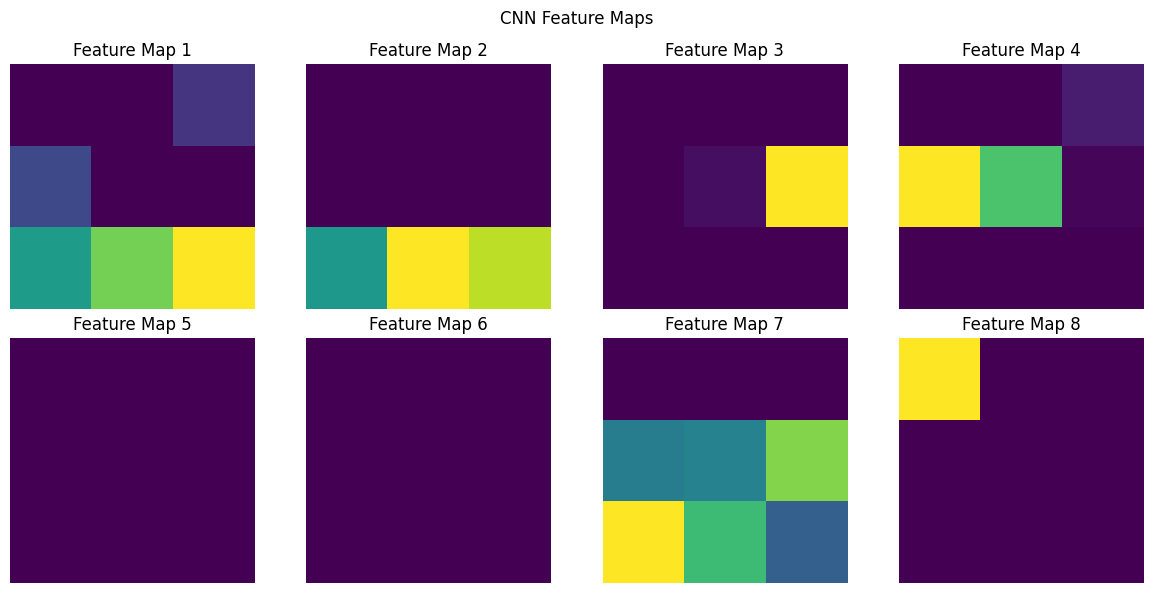


CONCLUSION

A Convolutional Neural Network was implemented using PyTorch
for classification of the FashionMNIST dataset.

The model achieved a final test accuracy of
92.09%.

The training and test accuracy curves demonstrate the learning
progress of the CNN, while the loss curves show how the
classification error changed during training.

The classification report provides precision, recall and
F1-score for each FashionMNIST category.

The confusion matrix shows which categories are most commonly
confused with one another. In particular, visually similar
clothing categories such as Shirt, T-shirt/top, Pullover and
Coat can be more difficult to distinguish.

The CNN feature maps demonstrate that the convolutional layers
learn useful visual patterns from the input images.

Overall, the CNN provides effective image classification on
FashionMNIST, and data normalization, augmentation, batch
normalization and dropout help improve generalization.



In [ ]:
# ============================================================
# FASHION-MNIST IMAGE CLASSIFICATION USING PYTORCH
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ------------------------------------------------------------
# 2. SET RANDOM SEED AND DEVICE
# ------------------------------------------------------------

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# ------------------------------------------------------------
# 3. LOAD AND PREPROCESS FASHIONMNIST
# ------------------------------------------------------------

# FashionMNIST pixel mean and standard deviation
mean = (0.2860,)
std = (0.3530,)

# Training transformations
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(28, padding=2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Test transformations
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


# Load training dataset
train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)


# Load test dataset
test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)


# Create DataLoaders
batch_size = 128

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# FashionMNIST class names
classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]


print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Number of classes:", len(classes))


# ------------------------------------------------------------
# 4. VISUALIZE SAMPLE IMAGES
# ------------------------------------------------------------

images, labels = next(iter(train_loader))


# Function to denormalize images
def denormalize(image):
    image = image * std[0]
    image = image + mean[0]
    return image


plt.figure(figsize=(10, 8))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    img = denormalize(images[i])
    img = torch.clamp(img, 0, 1)

    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(classes[labels[i]])
    plt.axis("off")

plt.suptitle("Sample FashionMNIST Images")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. DEFINE CNN MODEL
# ------------------------------------------------------------

class FashionMNISTCNN(nn.Module):

    def __init__(self):

        super(FashionMNISTCNN, self).__init__()

        self.features = nn.Sequential(

            # First convolution block
            nn.Conv2d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(
                in_channels=32,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout(0.25),


            # Second convolution block
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(
                in_channels=64,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout(0.25),


            # Third convolution block
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )


        self.classifier = nn.Sequential(

            nn.Flatten(),

            # 28x28 -> 14x14 -> 7x7 -> 3x3
            nn.Linear(128 * 3 * 3, 256),

            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(256, 10)
        )


    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


# Create model
model = FashionMNISTCNN().to(device)

print(model)


# ------------------------------------------------------------
# 6. LOSS FUNCTION AND OPTIMIZER
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)


# ------------------------------------------------------------
# 7. TRAINING FUNCTION
# ------------------------------------------------------------

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    running_loss = 0.0

    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()


    epoch_loss = running_loss / total

    epoch_accuracy = (
        100 * correct / total
    )

    return epoch_loss, epoch_accuracy


# ------------------------------------------------------------
# 8. EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0.0

    correct = 0
    total = 0

    all_predictions = []
    all_labels = []


    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()


            all_predictions.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )


    epoch_loss = running_loss / total

    epoch_accuracy = (
        100 * correct / total
    )


    return (
        epoch_loss,
        epoch_accuracy,
        np.array(all_labels),
        np.array(all_predictions)
    )


# ------------------------------------------------------------
# 9. TRAIN THE MODEL
# ------------------------------------------------------------

num_epochs = 15

train_losses = []
train_accuracies = []

test_losses = []
test_accuracies = []

best_accuracy = 0.0


print("\nStarting training...\n")


for epoch in range(num_epochs):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )


    test_loss, test_accuracy, _, _ = evaluate(
        model,
        test_loader,
        criterion
    )


    # Adjust learning rate
    scheduler.step(test_loss)


    # Store results
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)


    # Save best model
    if test_accuracy > best_accuracy:

        best_accuracy = test_accuracy

        torch.save(
            model.state_dict(),
            "best_fashionmnist_model.pth"
        )


    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Accuracy: {train_accuracy:.2f}% "
        f"| Test Loss: {test_loss:.4f} "
        f"| Test Accuracy: {test_accuracy:.2f}%"
    )


print("\nTraining completed.")

print(
    f"Best Test Accuracy: "
    f"{best_accuracy:.2f}%"
)


# ------------------------------------------------------------
# 10. LOAD BEST MODEL
# ------------------------------------------------------------

model.load_state_dict(
    torch.load(
        "best_fashionmnist_model.pth",
        map_location=device
    )
)

model.eval()


# ------------------------------------------------------------
# 11. FINAL EVALUATION
# ------------------------------------------------------------

test_loss, test_accuracy, y_true, y_pred = evaluate(
    model,
    test_loader,
    criterion
)


print("\n================================")
print("FINAL TEST RESULTS")
print("================================")

print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : {test_accuracy:.2f}%"
)


# ------------------------------------------------------------
# 12. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n================================")
print("CLASSIFICATION REPORT")
print("================================")


print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes,
        digits=4
    )
)


# ------------------------------------------------------------
# 13. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred
)


fig, ax = plt.subplots(
    figsize=(10, 8)
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)


disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)


plt.title(
    "FashionMNIST Confusion Matrix"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. TRAINING AND TEST LOSS GRAPH
# ------------------------------------------------------------

epochs = range(
    1,
    num_epochs + 1
)


plt.figure(figsize=(8, 5))


plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)


plt.plot(
    epochs,
    test_losses,
    marker="o",
    label="Test Loss"
)


plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title(
    "Training and Test Loss"
)

plt.legend()

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 15. TRAINING AND TEST ACCURACY GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))


plt.plot(
    epochs,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)


plt.plot(
    epochs,
    test_accuracies,
    marker="o",
    label="Test Accuracy"
)


plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title(
    "Training and Test Accuracy"
)

plt.legend()

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 16. DISPLAY MODEL PREDICTIONS
# ------------------------------------------------------------

images, labels = next(
    iter(test_loader)
)


images_gpu = images.to(device)


with torch.no_grad():

    outputs = model(
        images_gpu
    )

    _, predictions = torch.max(
        outputs,
        1
    )


plt.figure(figsize=(10, 8))


for i in range(16):

    plt.subplot(4, 4, i + 1)


    img = denormalize(
        images[i]
    )

    img = torch.clamp(
        img,
        0,
        1
    )


    plt.imshow(
        img.squeeze(),
        cmap="gray"
    )


    true_label = classes[
        labels[i]
    ]


    predicted_label = classes[
        predictions[i].cpu()
    ]


    plt.title(
        f"True: {true_label}\n"
        f"Pred: {predicted_label}",
        fontsize=9
    )


    plt.axis("off")


plt.suptitle(
    "FashionMNIST Predictions"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 17. PER-CLASS ACCURACY
# ------------------------------------------------------------

print("\n================================")
print("PER-CLASS ACCURACY")
print("================================")


for i, class_name in enumerate(classes):

    class_mask = (
        y_true == i
    )


    class_correct = np.sum(
        y_pred[class_mask] == i
    )


    class_total = np.sum(
        class_mask
    )


    class_accuracy = (
        100 *
        class_correct /
        class_total
    )


    print(
        f"{class_name:15s}: "
        f"{class_accuracy:.2f}%"
    )


# ------------------------------------------------------------
# 18. EXTRACT AND VISUALIZE CNN FEATURES
# ------------------------------------------------------------

# Take one test image
sample_image = images[0:1].to(device)


# Extract features from convolutional layers
with torch.no_grad():

    feature_maps = model.features(
        sample_image
    )


print(
    "\nFeature map shape:",
    feature_maps.shape
)


# Display first 8 feature maps
plt.figure(figsize=(12, 6))


for i in range(8):

    plt.subplot(2, 4, i + 1)

    plt.imshow(
        feature_maps[0, i].cpu(),
        cmap="viridis"
    )

    plt.title(
        f"Feature Map {i + 1}"
    )

    plt.axis("off")


plt.suptitle(
    "CNN Feature Maps"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 19. FINAL CONCLUSION
# ------------------------------------------------------------

print("\n================================")
print("CONCLUSION")
print("================================")


print(f"""
A Convolutional Neural Network was implemented using PyTorch
for classification of the FashionMNIST dataset.

The model achieved a final test accuracy of
{test_accuracy:.2f}%.

The training and test accuracy curves demonstrate the learning
progress of the CNN, while the loss curves show how the
classification error changed during training.

The classification report provides precision, recall and
F1-score for each FashionMNIST category.

The confusion matrix shows which categories are most commonly
confused with one another. In particular, visually similar
clothing categories such as Shirt, T-shirt/top, Pullover and
Coat can be more difficult to distinguish.

The CNN feature maps demonstrate that the convolutional layers
learn useful visual patterns from the input images.

Overall, the CNN provides effective image classification on
FashionMNIST, and data normalization, augmentation, batch
normalization and dropout help improve generalization.
""")

Using device: cuda
GPU: Tesla T4
This may take some time because the dataset is large.
Using Colab cache for faster access to the 'kaggle-cat-vs-dog-dataset' dataset.
Dataset downloaded successfully.
Downloaded location:
/kaggle/input/kaggle-cat-vs-dog-dataset

Dataset path: /kaggle/input/kaggle-cat-vs-dog-dataset/kagglecatsanddogs_3367a/PetImages
Folders: ['Dog', 'Cat']

Checking image files...
This may take a little time.


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))



Total valid images: 24959
Classes: ['Cat', 'Dog']

Training images: 19967
Testing images : 4992

DataLoaders created successfully.


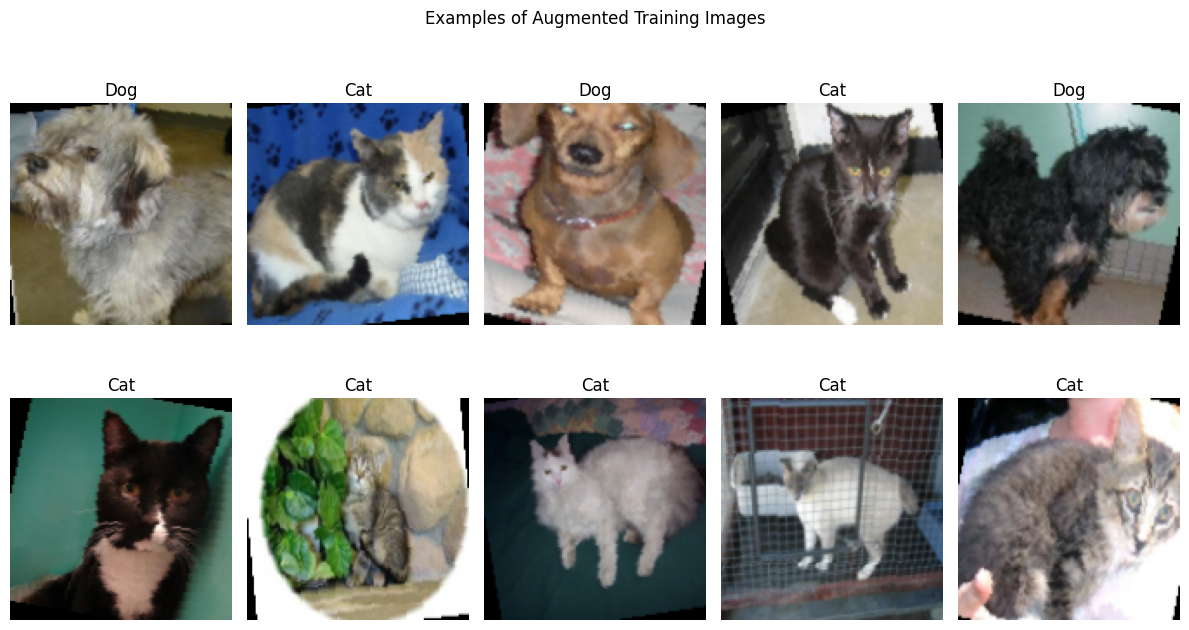


CNN Model:
CatsDogsCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=2, bias=True)
  )
)

Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.001
Epoch [1/5] Loss: 0.6310 Accuracy: 63.37%
Epoch [2/5] Loss: 0.5316 Accuracy: 73.24%
Epoch [3/5]

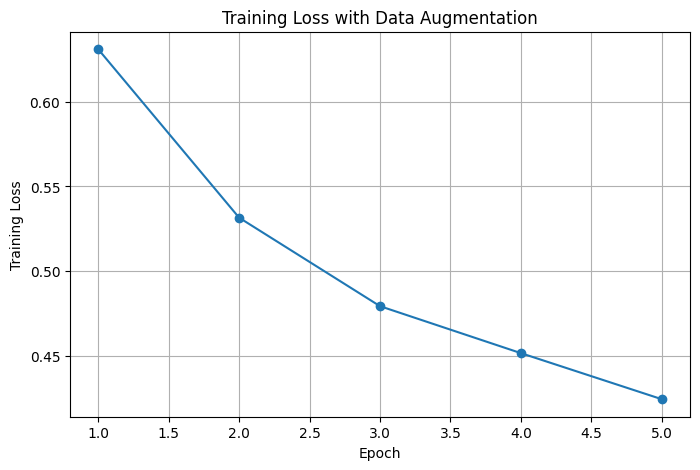

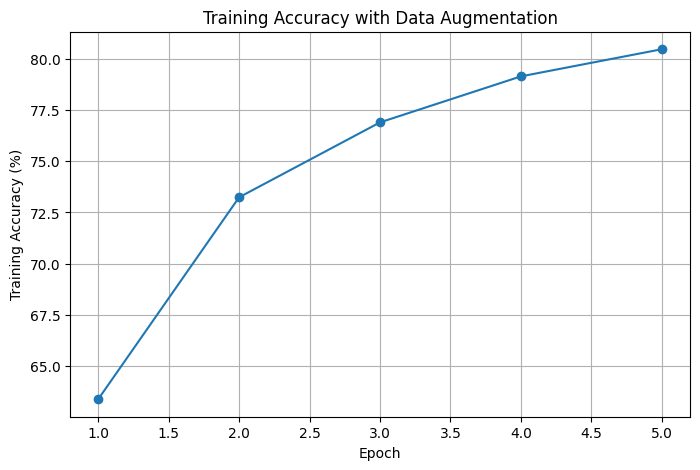

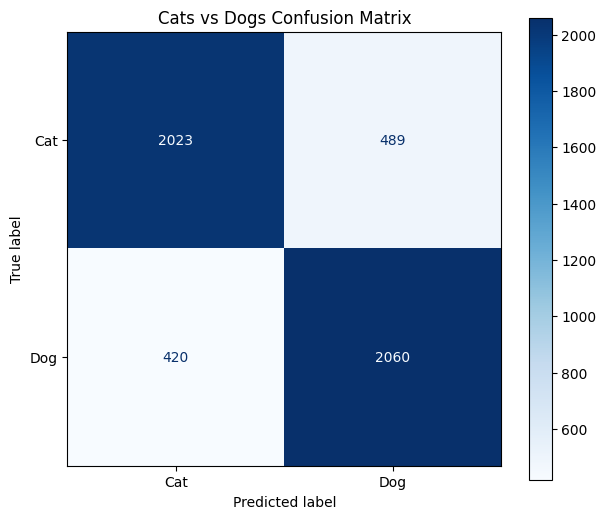

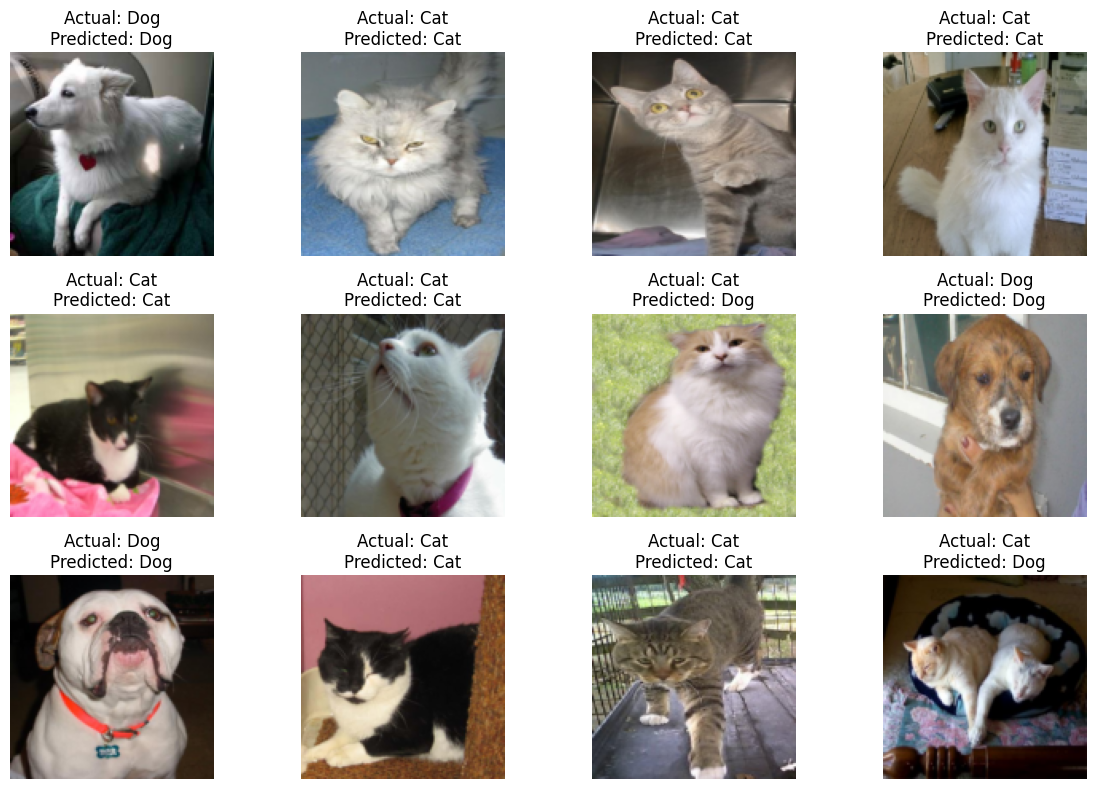


FINAL RESULTS
Test Accuracy : 81.79%
Precision     : 81.82%
Recall        : 81.79%
F1 Score      : 81.79%

CONCLUSION

The Cats vs Dogs dataset was successfully loaded and
preprocessed using PyTorch.

Data augmentation techniques including Random Horizontal
Flip, Random Rotation and Random Resized Crop were applied
to the training images.

A Convolutional Neural Network (CNN) was implemented for
binary classification of cats and dogs.

The model was trained using the Adam optimizer and
CrossEntropyLoss.

The training loss and accuracy were recorded for every
epoch and visualized using graphs.

The model was evaluated using Accuracy, Precision,
Recall and F1 Score.

A confusion matrix was also generated to understand
the classification performance of the model.

Data augmentation provides different variations of the
training images and helps the CNN learn more general
visual features. This can help reduce overfitting and
improve performance on unseen images.

Overall, the CNN successfu

In [ ]:
# ============================================================
# IMPLEMENTING DATA AUGMENTATION FOR IMAGE DATA
# CATS VS DOGS CLASSIFICATION USING PYTORCH
# ============================================================


# ============================================================
# 1. INSTALL AND IMPORT REQUIRED LIBRARIES
# ============================================================

!pip -q install kagglehub

import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split, Subset

from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# 2. SET RANDOM SEED AND DEVICE
# ============================================================

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 3. DOWNLOAD CATS VS DOGS DATASET
# ============================================================

import kagglehub

print("Downloading Cats vs Dogs dataset...")
print("This may take some time because the dataset is large.")

dataset_download_path = kagglehub.dataset_download(
    "karakaggle/kaggle-cat-vs-dog-dataset"
)

print("Dataset downloaded successfully.")
print("Downloaded location:")
print(dataset_download_path)


# ============================================================
# 4. FIND PETIMAGES FOLDER
# ============================================================

dataset_path = None

for root, dirs, files in os.walk(dataset_download_path):

    folder_names = [d.lower() for d in dirs]

    if "cat" in folder_names and "dog" in folder_names:

        dataset_path = root
        break


if dataset_path is None:

    raise FileNotFoundError(
        "Could not find Cat and Dog folders in the dataset."
    )


print("\nDataset path:", dataset_path)
print("Folders:", os.listdir(dataset_path))


# ============================================================
# 5. CHECK IMAGE FILES
# ============================================================

def check_image(path):

    try:

        with Image.open(path) as img:
            img.verify()

        return True

    except:

        return False


print("\nChecking image files...")
print("This may take a little time.")


# ============================================================
# 6. DATA AUGMENTATION FOR TRAINING
# ============================================================

train_transform = transforms.Compose([

    # Resize image
    transforms.Resize((128, 128)),

    # ----------------------------
    # DATA AUGMENTATION
    # ----------------------------

    # Randomly flip image horizontally
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    # Randomly rotate image
    transforms.RandomRotation(
        15
    ),

    # Randomly crop and resize
    transforms.RandomResizedCrop(
        128,
        scale=(0.8, 1.0)
    ),

    # Convert image to tensor
    transforms.ToTensor(),

    # Normalize image
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])


# ============================================================
# 7. PREPROCESSING FOR TEST DATA
# ============================================================

# No random augmentation is applied to test images.

test_transform = transforms.Compose([

    transforms.Resize((128, 128)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])


# ============================================================
# 8. LOAD TRAINING DATASET
# ============================================================

train_full_dataset = ImageFolder(
    root=dataset_path,
    transform=train_transform,
    is_valid_file=check_image
)

print("\nTotal valid images:", len(train_full_dataset))
print("Classes:", train_full_dataset.classes)

# Expected:
# ['Cat', 'Dog']


# ============================================================
# 9. LOAD TEST DATASET
# ============================================================

test_full_dataset = ImageFolder(
    root=dataset_path,
    transform=test_transform,
    is_valid_file=check_image
)


# ============================================================
# 10. SPLIT DATASET
# ============================================================

total_size = len(train_full_dataset)

train_size = int(
    0.8 * total_size
)

test_size = total_size - train_size


# Create the same random indices for both datasets
generator = torch.Generator().manual_seed(42)

train_subset, test_subset = random_split(
    range(total_size),
    [train_size, test_size],
    generator=generator
)


# Create actual datasets using the same indices
train_dataset = Subset(
    train_full_dataset,
    train_subset.indices
)

test_dataset = Subset(
    test_full_dataset,
    test_subset.indices
)


print("\nTraining images:", len(train_dataset))
print("Testing images :", len(test_dataset))


# ============================================================
# 11. CREATE DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nDataLoaders created successfully.")


# ============================================================
# 12. DISPLAY AUGMENTED IMAGES
# ============================================================

images, labels = next(
    iter(train_loader)
)

plt.figure(figsize=(12, 7))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    image = images[i]

    # Convert normalized image back
    image = image * 0.5 + 0.5

    image = image.permute(
        1, 2, 0
    )

    image = torch.clamp(
        image,
        0,
        1
    )

    plt.imshow(image)

    if labels[i].item() == 0:
        title = "Cat"
    else:
        title = "Dog"

    plt.title(title)

    plt.axis("off")

plt.suptitle(
    "Examples of Augmented Training Images"
)

plt.tight_layout()
plt.show()


# ============================================================
# 13. BUILD CNN MODEL
# ============================================================

class CatsDogsCNN(nn.Module):

    def __init__(self):

        super(CatsDogsCNN, self).__init__()

        # ----------------------------------------------------
        # CONVOLUTIONAL FEATURE EXTRACTION
        # ----------------------------------------------------

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            ),


            # Block 2
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            ),


            # Block 3
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            )
        )


        # ----------------------------------------------------
        # CLASSIFICATION
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Flatten(),

            # 128 x 16 x 16
            nn.Linear(
                128 * 16 * 16,
                256
            ),

            nn.ReLU(),

            # Dropout helps prevent overfitting
            nn.Dropout(
                0.5
            ),

            # Binary classification
            nn.Linear(
                256,
                2
            )
        )


    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


# Create model
model = CatsDogsCNN().to(device)

print("\nCNN Model:")
print(model)


# ============================================================
# 14. DEFINE LOSS FUNCTION AND OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("\nLoss Function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning Rate: 0.001")


# ============================================================
# 15. TRAIN THE MODEL
# ============================================================

epochs = 5

train_losses = []
train_accuracies = []


for epoch in range(epochs):

    model.train()

    running_loss = 0.0

    correct = 0
    total = 0


    for images, labels in train_loader:

        # Move data to GPU/CPU
        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        # --------------------------------------------
        # CLEAR GRADIENTS
        # --------------------------------------------

        optimizer.zero_grad()


        # --------------------------------------------
        # FORWARD PASS
        # --------------------------------------------

        outputs = model(images)


        # --------------------------------------------
        # CALCULATE LOSS
        # --------------------------------------------

        loss = criterion(
            outputs,
            labels
        )


        # --------------------------------------------
        # BACKPROPAGATION
        # --------------------------------------------

        loss.backward()


        # --------------------------------------------
        # UPDATE WEIGHTS
        # --------------------------------------------

        optimizer.step()


        # --------------------------------------------
        # STORE LOSS
        # --------------------------------------------

        running_loss += loss.item()


        # --------------------------------------------
        # CALCULATE ACCURACY
        # --------------------------------------------

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()


    # Calculate epoch results
    epoch_loss = (
        running_loss /
        len(train_loader)
    )

    epoch_accuracy = (
        100 * correct / total
    )


    train_losses.append(
        epoch_loss
    )

    train_accuracies.append(
        epoch_accuracy
    )


    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )


# ============================================================
# 16. EVALUATE THE MODEL
# ============================================================

model.eval()

y_true = []
y_pred = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        _, predicted = torch.max(
            outputs,
            1
        )


        y_true.extend(
            labels.numpy()
        )

        y_pred.extend(
            predicted.cpu().numpy()
        )


# ============================================================
# 17. CALCULATE PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)


# ============================================================
# 18. DISPLAY EVALUATION RESULTS
# ============================================================

print("\n============================================================")
print("EVALUATION RESULTS")
print("============================================================")

print(
    f"Accuracy  : {accuracy * 100:.2f}%"
)

print(
    f"Precision : {precision * 100:.2f}%"
)

print(
    f"Recall    : {recall * 100:.2f}%"
)

print(
    f"F1 Score  : {f1 * 100:.2f}%"
)


# ============================================================
# 19. PLOT TRAINING LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.title(
    "Training Loss with Data Augmentation"
)

plt.grid()

plt.show()


# ============================================================
# 20. PLOT TRAINING ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_accuracies,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")

plt.title(
    "Training Accuracy with Data Augmentation"
)

plt.grid()

plt.show()


# ============================================================
# 21. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

disp.plot(
    ax=ax,
    cmap="Blues"
)

plt.title(
    "Cats vs Dogs Confusion Matrix"
)

plt.show()


# ============================================================
# 22. DISPLAY ACTUAL VS PREDICTED IMAGES
# ============================================================

images, labels = next(
    iter(test_loader)
)

images_device = images.to(device)


with torch.no_grad():

    outputs = model(
        images_device
    )

    _, predictions = torch.max(
        outputs,
        1
    )


plt.figure(figsize=(12, 8))


for i in range(12):

    plt.subplot(
        3,
        4,
        i + 1
    )


    # Convert image back
    image = images[i]

    image = image * 0.5 + 0.5

    image = image.permute(
        1,
        2,
        0
    )

    image = torch.clamp(
        image,
        0,
        1
    )


    plt.imshow(image)


    # Actual label
    if labels[i].item() == 0:
        actual = "Cat"
    else:
        actual = "Dog"


    # Predicted label
    if predictions[i].item() == 0:
        predicted = "Cat"
    else:
        predicted = "Dog"


    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()


# ============================================================
# 23. FINAL RESULTS
# ============================================================

print("\n============================================================")
print("FINAL RESULTS")
print("============================================================")

print(
    f"Test Accuracy : {accuracy * 100:.2f}%"
)

print(
    f"Precision     : {precision * 100:.2f}%"
)

print(
    f"Recall        : {recall * 100:.2f}%"
)

print(
    f"F1 Score      : {f1 * 100:.2f}%"
)


# ============================================================
# 24. CONCLUSION
# ============================================================

print("\n============================================================")
print("CONCLUSION")
print("============================================================")

print("""
The Cats vs Dogs dataset was successfully loaded and
preprocessed using PyTorch.

Data augmentation techniques including Random Horizontal
Flip, Random Rotation and Random Resized Crop were applied
to the training images.

A Convolutional Neural Network (CNN) was implemented for
binary classification of cats and dogs.

The model was trained using the Adam optimizer and
CrossEntropyLoss.

The training loss and accuracy were recorded for every
epoch and visualized using graphs.

The model was evaluated using Accuracy, Precision,
Recall and F1 Score.

A confusion matrix was also generated to understand
the classification performance of the model.

Data augmentation provides different variations of the
training images and helps the CNN learn more general
visual features. This can help reduce overfitting and
improve performance on unseen images.

Overall, the CNN successfully learned to distinguish
between cats and dogs using augmented image data.
""")

Using device: cuda

Downloading/loading CIFAR-10 dataset...


100%|██████████| 170M/170M [20:08<00:00, 141kB/s]


Training samples: 50000
Testing samples : 10000


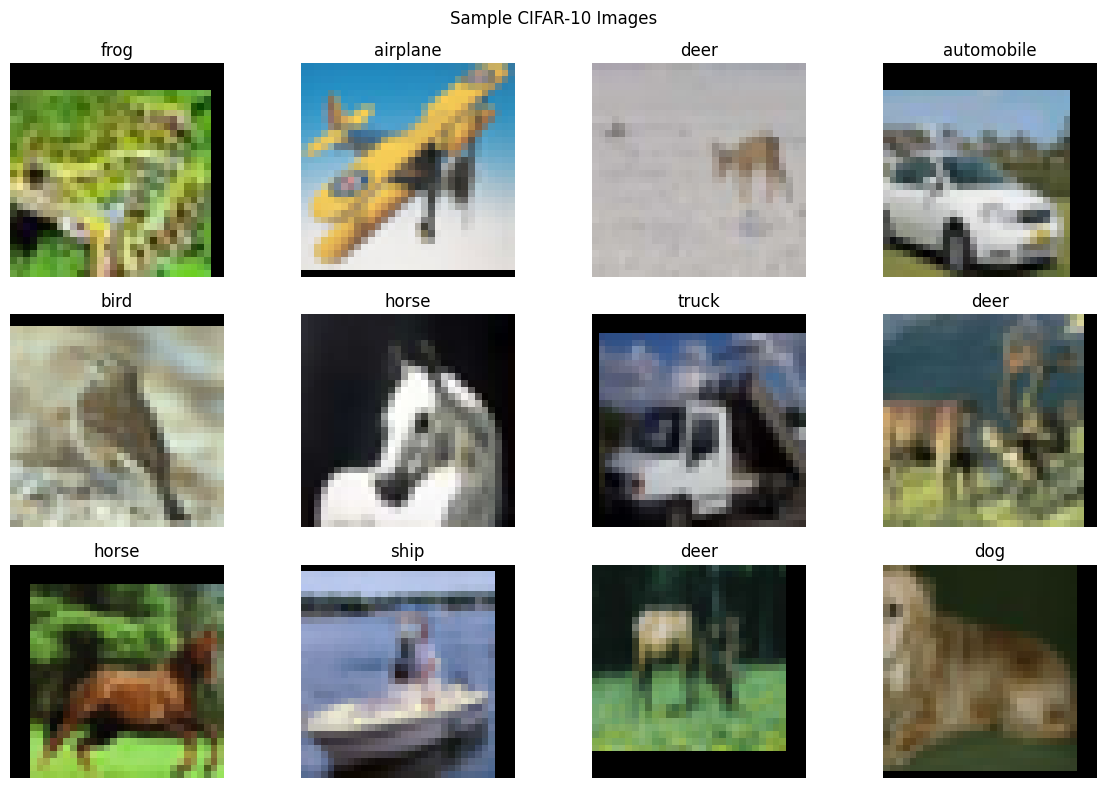


================ MODEL ================

CIFAR10CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.25, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_

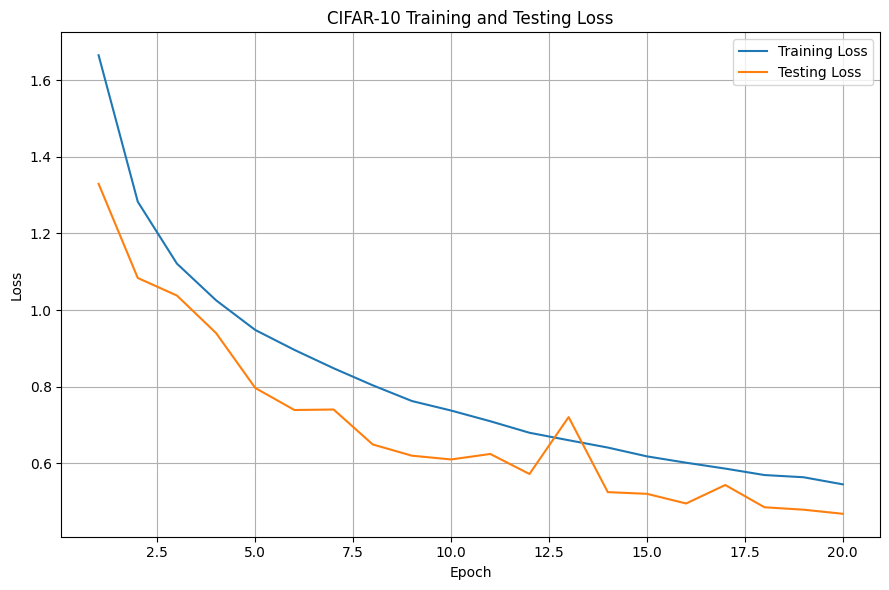

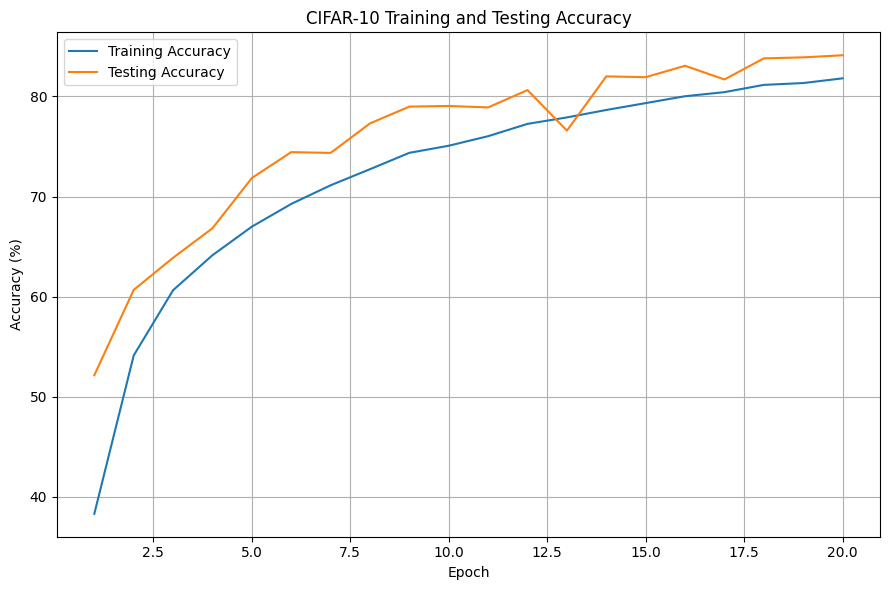


================ CLASSIFICATION REPORT ================

              precision    recall  f1-score   support

    airplane     0.8745    0.8080    0.8399      1000
  automobile     0.9317    0.9280    0.9299      1000
        bird     0.6858    0.8470    0.7579      1000
         cat     0.7590    0.6770    0.7156      1000
        deer     0.8054    0.8690    0.8360      1000
         dog     0.8406    0.6750    0.7488      1000
        frog     0.8275    0.9260    0.8740      1000
       horse     0.8910    0.8830    0.8870      1000
        ship     0.9265    0.8830    0.9042      1000
       truck     0.9087    0.9160    0.9124      1000

    accuracy                         0.8412     10000
   macro avg     0.8451    0.8412    0.8406     10000
weighted avg     0.8451    0.8412    0.8406     10000



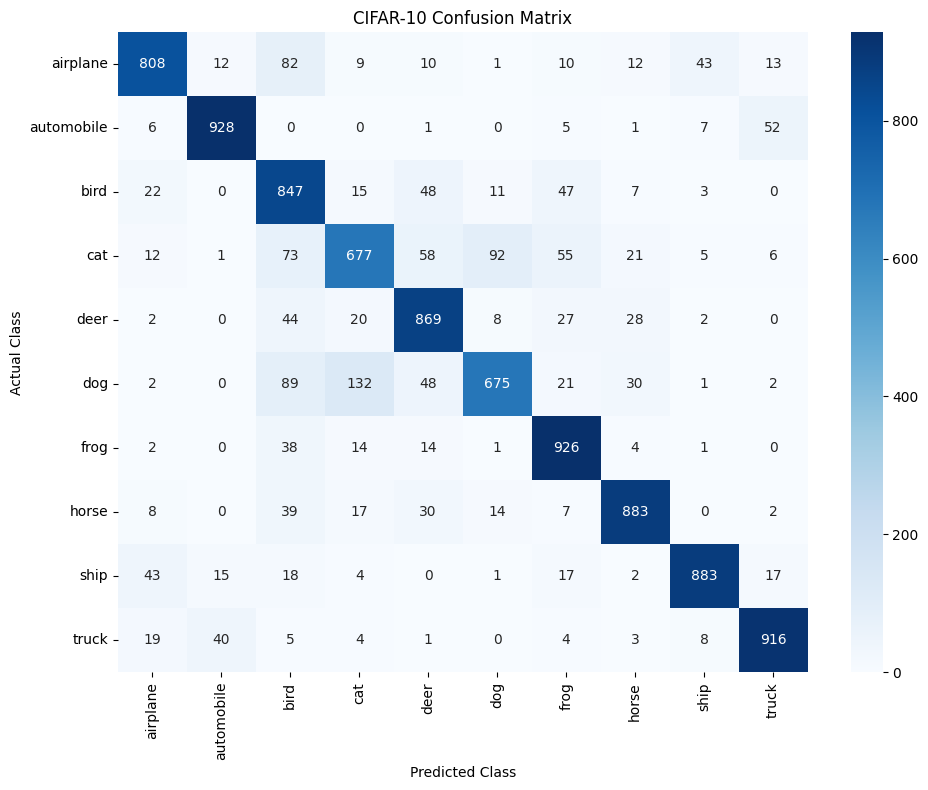


================ CLASS-WISE ACCURACY ================

airplane    : 80.80%
automobile  : 92.80%
bird        : 84.70%
cat         : 67.70%
deer        : 86.90%
dog         : 67.50%
frog        : 92.60%
horse       : 88.30%
ship        : 88.30%
truck       : 91.60%


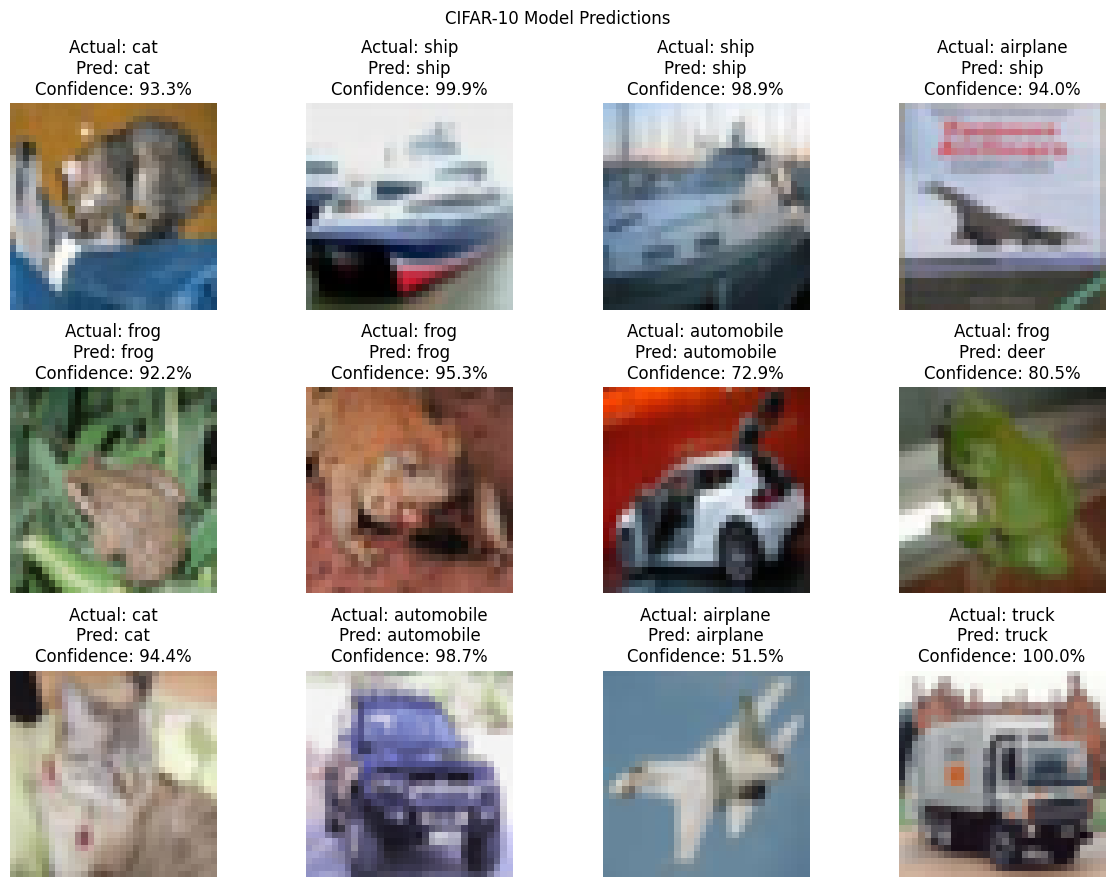


Number of incorrect predictions: 1588


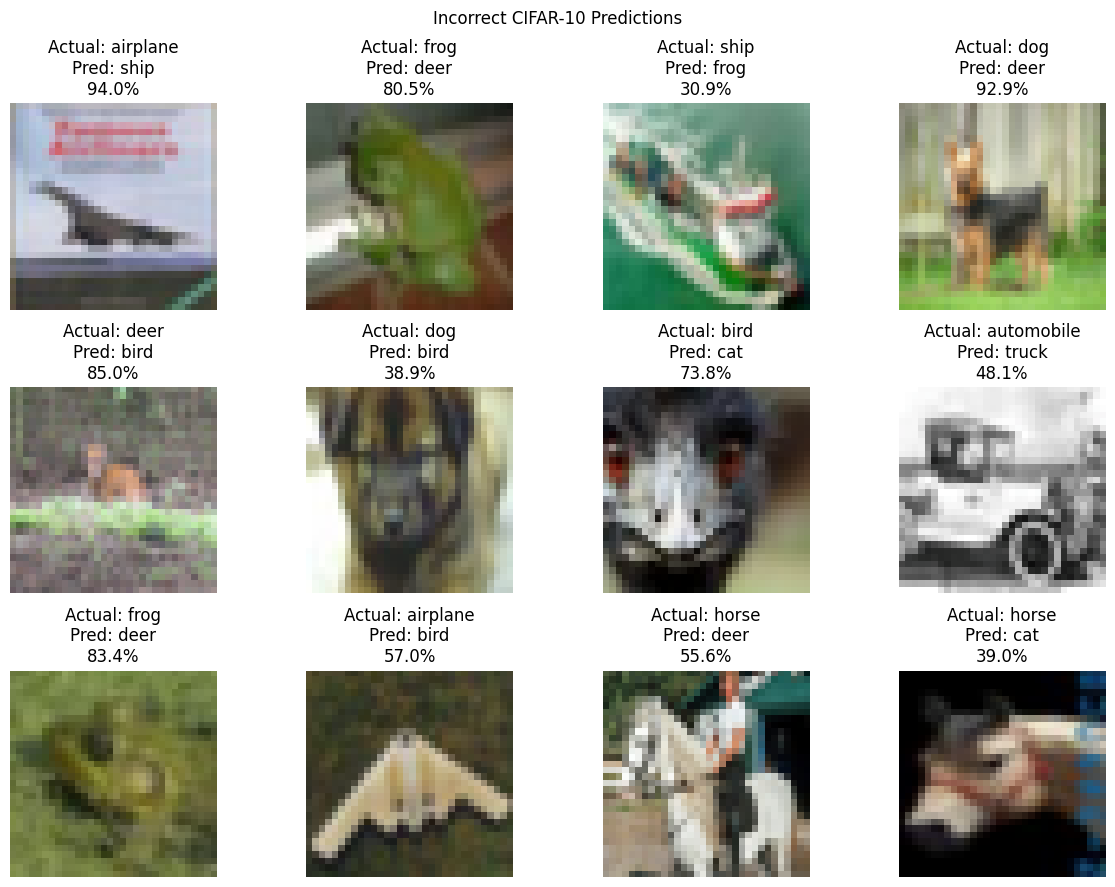

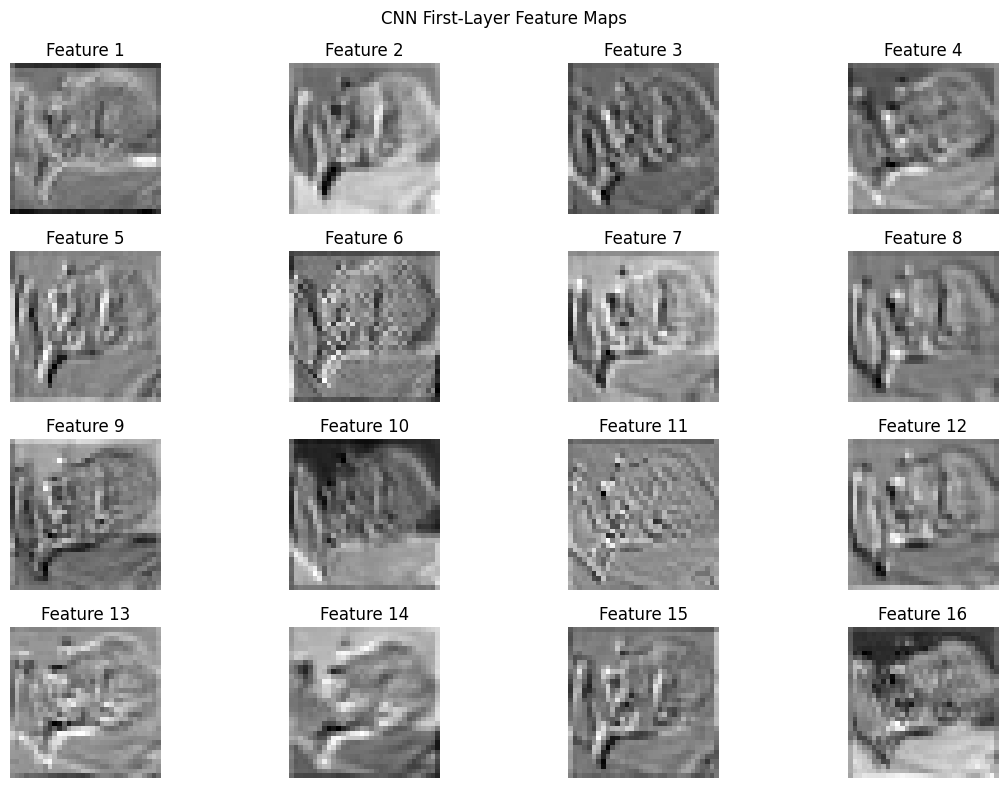


================ SINGLE IMAGE PREDICTION ================

Actual class    : cat
Predicted class : cat
Confidence      : 93.26%


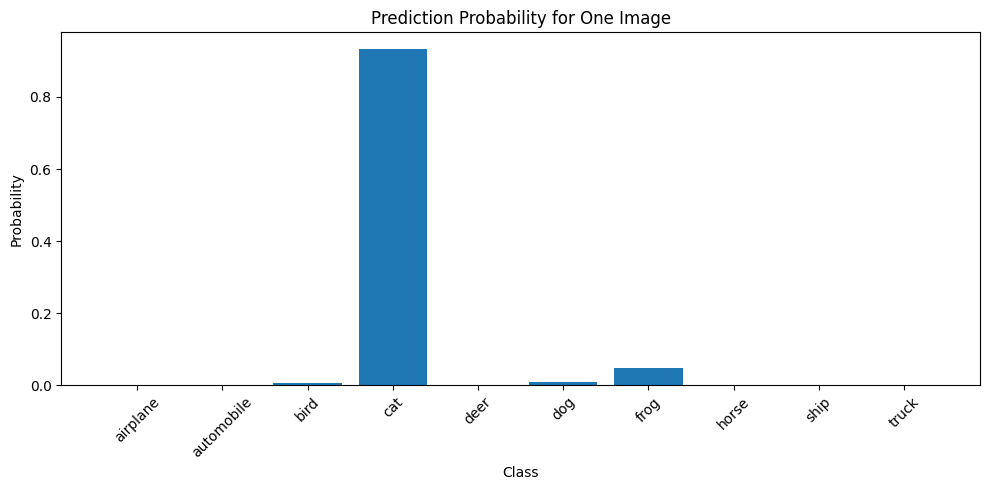


Model saved as: cifar10_cnn.pth
Saved model loaded successfully.


CIFAR-10 CNN TRAINING SUMMARY
Training samples : 50000
Testing samples  : 10000
Batch size       : 128
Epochs           : 20
Optimizer        : Adam
Initial LR       : 0.001
Weight decay     : 0.0001
Final train acc  : 81.81%
Final test acc   : 84.12%
Final train loss : 0.5454
Final test loss  : 0.4685

Training and evaluation completed successfully.


In [ ]:
# ============================================================
# CIFAR-10 IMAGE CLASSIFICATION USING PYTORCH
# ============================================================
#
# 1. Load and preprocess CIFAR-10
# 2. Implement CNN model
# 3. Train the model
# 4. Evaluate using accuracy, precision, recall and F1-score
# 5. Visualize loss, accuracy, predictions, confusion matrix
# 6. Visualize CNN feature maps
# 7. Save the trained model
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)


# ============================================================
# 2. SET RANDOM SEED AND DEVICE
# ============================================================

torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)


# ============================================================
# 3. CIFAR-10 CLASS NAMES
# ============================================================

classes = (
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
)


# ============================================================
# 4. DATA PREPROCESSING
# ============================================================

# CIFAR-10 mean and standard deviation
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)


# Training transformations
# RandomCrop and RandomHorizontalFlip are data augmentation
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        CIFAR10_MEAN,
        CIFAR10_STD
    )
])


# Testing transformations
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        CIFAR10_MEAN,
        CIFAR10_STD
    )
])


# ============================================================
# 5. LOAD CIFAR-10 DATASET
# ============================================================

print("\nDownloading/loading CIFAR-10 dataset...")

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)


print("Training samples:", len(train_dataset))
print("Testing samples :", len(test_dataset))


# ============================================================
# 6. CREATE DATA LOADERS
# ============================================================

BATCH_SIZE = 128

# num_workers=0 works reliably on Windows, macOS and Colab
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)


# ============================================================
# 7. DISPLAY SAMPLE IMAGES
# ============================================================

def denormalize(image):
    """
    Convert a normalized CIFAR-10 image back to
    its original range for visualization.
    """

    mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR10_STD).view(3, 1, 1)

    image = image.cpu() * std + mean

    return torch.clamp(image, 0, 1)


# Get one batch
images, labels = next(iter(train_loader))


plt.figure(figsize=(12, 8))

for i in range(12):

    plt.subplot(3, 4, i + 1)

    image = denormalize(images[i])

    plt.imshow(
        np.transpose(
            image.numpy(),
            (1, 2, 0)
        )
    )

    plt.title(classes[labels[i].item()])
    plt.axis("off")

plt.suptitle("Sample CIFAR-10 Images")
plt.tight_layout()
plt.show()


# ============================================================
# 8. DEFINE CNN MODEL
# ============================================================

class CIFAR10CNN(nn.Module):

    def __init__(self):

        super(CIFAR10CNN, self).__init__()

        # ----------------------------------------------------
        # CONVOLUTIONAL FEATURE EXTRACTION
        # ----------------------------------------------------

        self.features = nn.Sequential(

            # -------------------------------
            # Block 1
            # Input: 3 x 32 x 32
            # -------------------------------

            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(),

            nn.Conv2d(
                in_channels=32,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2),

            nn.Dropout(0.25),


            # -------------------------------
            # Block 2
            # 32 x 16 x 16
            # -------------------------------

            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(),

            nn.Conv2d(
                in_channels=64,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2),

            nn.Dropout(0.25),


            # -------------------------------
            # Block 3
            # 64 x 8 x 8
            # -------------------------------

            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(),

            nn.Conv2d(
                in_channels=128,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2),

            nn.Dropout(0.25)
        )


        # ----------------------------------------------------
        # FULLY CONNECTED CLASSIFIER
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            # After 3 max-pooling layers:
            #
            # 32 x 32
            #     ↓
            # 16 x 16
            #     ↓
            # 8 x 8
            #     ↓
            # 4 x 4
            #
            # Number of features = 128 * 4 * 4

            nn.Flatten(),

            nn.Linear(
                128 * 4 * 4,
                256
            ),

            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(
                256,
                10
            )
        )


    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


# ============================================================
# 9. CREATE MODEL
# ============================================================

model = CIFAR10CNN().to(device)

print("\n================ MODEL ================\n")
print(model)


# Count trainable parameters
total_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal trainable parameters:", total_parameters)


# ============================================================
# 10. LOSS FUNCTION
# ============================================================

criterion = nn.CrossEntropyLoss()


# ============================================================
# 11. OPTIMIZER
# ============================================================

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)


# ============================================================
# 12. LEARNING RATE SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)


# ============================================================
# 13. TRAINING PARAMETERS
# ============================================================

NUM_EPOCHS = 20

train_losses = []
test_losses = []

train_accuracies = []
test_accuracies = []


# ============================================================
# 14. TRAINING LOOP
# ============================================================

print("\n================ TRAINING ================\n")

for epoch in range(NUM_EPOCHS):

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    model.train()

    running_train_loss = 0.0

    train_correct = 0
    train_total = 0


    for images, labels in train_loader:

        # Move data to GPU/CPU
        images = images.to(device)
        labels = labels.to(device)


        # Clear previous gradients
        optimizer.zero_grad()


        # Forward pass
        outputs = model(images)


        # Calculate loss
        loss = criterion(
            outputs,
            labels
        )


        # Backpropagation
        loss.backward()


        # Update weights
        optimizer.step()


        # Accumulate loss
        running_train_loss += loss.item()


        # Calculate accuracy
        _, predicted = torch.max(
            outputs,
            1
        )

        train_total += labels.size(0)

        train_correct += (
            predicted == labels
        ).sum().item()


    # Average training loss
    train_loss = (
        running_train_loss /
        len(train_loader)
    )


    # Training accuracy
    train_accuracy = (
        100.0 *
        train_correct /
        train_total
    )


    # --------------------------------------------------------
    # TESTING
    # --------------------------------------------------------

    model.eval()

    running_test_loss = 0.0

    test_correct = 0
    test_total = 0


    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)


            # Forward pass
            outputs = model(images)


            # Loss
            loss = criterion(
                outputs,
                labels
            )


            running_test_loss += loss.item()


            # Predictions
            _, predicted = torch.max(
                outputs,
                1
            )


            test_total += labels.size(0)

            test_correct += (
                predicted == labels
            ).sum().item()


    # Average test loss
    test_loss = (
        running_test_loss /
        len(test_loader)
    )


    # Test accuracy
    test_accuracy = (
        100.0 *
        test_correct /
        test_total
    )


    # Update learning rate
    scheduler.step(test_loss)


    # Store values
    train_losses.append(train_loss)
    test_losses.append(test_loss)

    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)


    # Current learning rate
    current_lr = optimizer.param_groups[0]["lr"]


    # Print epoch results
    print(
        f"Epoch [{epoch + 1:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_accuracy:.2f}% | "
        f"LR: {current_lr:.6f}"
    )


# ============================================================
# 15. FINAL TEST ACCURACY
# ============================================================

print("\n================ FINAL RESULT ================\n")

print(
    f"Final Test Accuracy: "
    f"{test_accuracies[-1]:.2f}%"
)


# ============================================================
# 16. PLOT TRAINING/TESTING LOSS
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, NUM_EPOCHS + 1),
    test_losses,
    label="Testing Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "CIFAR-10 Training and Testing Loss"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 17. PLOT TRAINING/TESTING ACCURACY
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    range(1, NUM_EPOCHS + 1),
    test_accuracies,
    label="Testing Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title(
    "CIFAR-10 Training and Testing Accuracy"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 18. COMPLETE MODEL EVALUATION
# ============================================================

model.eval()

all_predictions = []
all_labels = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)


        outputs = model(images)


        _, predictions = torch.max(
            outputs,
            1
        )


        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )


all_predictions = np.array(
    all_predictions
)

all_labels = np.array(
    all_labels
)


# ============================================================
# 19. CLASSIFICATION REPORT
# ============================================================

print("\n================ CLASSIFICATION REPORT ================\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=classes,
        digits=4
    )
)


# ============================================================
# 20. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_labels,
    all_predictions
)


plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.title(
    "CIFAR-10 Confusion Matrix"
)

plt.tight_layout()

plt.show()


# ============================================================
# 21. CLASS-WISE ACCURACY
# ============================================================

print("\n================ CLASS-WISE ACCURACY ================\n")

for i, class_name in enumerate(classes):

    class_total = cm[i].sum()

    class_correct = cm[i, i]

    class_accuracy = (
        100.0 *
        class_correct /
        class_total
    )

    print(
        f"{class_name:12s}: "
        f"{class_accuracy:.2f}%"
    )


# ============================================================
# 22. DISPLAY CORRECT PREDICTIONS
# ============================================================

# Load test data again
# without training augmentation

visual_test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)

visual_test_loader = DataLoader(
    visual_test_dataset,
    batch_size=32,
    shuffle=False
)


images, labels = next(
    iter(visual_test_loader)
)


images_device = images.to(device)


model.eval()

with torch.no_grad():

    outputs = model(
        images_device
    )

    probabilities = torch.softmax(
        outputs,
        dim=1
    )

    predictions = torch.argmax(
        probabilities,
        dim=1
    )


plt.figure(figsize=(12, 9))

for i in range(12):

    plt.subplot(3, 4, i + 1)

    image = denormalize(
        images[i]
    )

    plt.imshow(
        np.transpose(
            image.numpy(),
            (1, 2, 0)
        )
    )


    actual = classes[
        labels[i].item()
    ]

    predicted = classes[
        predictions[i].item()
    ]


    confidence = (
        probabilities[i][
            predictions[i]
        ].item() * 100
    )


    plt.title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}\n"
        f"Confidence: {confidence:.1f}%"
    )

    plt.axis("off")


plt.suptitle(
    "CIFAR-10 Model Predictions"
)

plt.tight_layout()

plt.show()


# ============================================================
# 23. DISPLAY INCORRECT PREDICTIONS
# ============================================================

incorrect_indices = np.where(
    all_predictions != all_labels
)[0]


print(
    "\nNumber of incorrect predictions:",
    len(incorrect_indices)
)


plt.figure(figsize=(12, 9))


# Display up to 12 incorrect predictions
num_images = min(
    12,
    len(incorrect_indices)
)


for i in range(num_images):

    index = incorrect_indices[i]

    # Get image from test dataset
    image, actual_label = (
        visual_test_dataset[index]
    )


    # Put image into batch
    image_batch = image.unsqueeze(
        0
    ).to(device)


    with torch.no_grad():

        output = model(
            image_batch
        )

        probability = torch.softmax(
            output,
            dim=1
        )

        prediction = torch.argmax(
            probability,
            dim=1
        ).item()


    plt.subplot(3, 4, i + 1)

    image_display = denormalize(
        image
    )


    plt.imshow(
        np.transpose(
            image_display.numpy(),
            (1, 2, 0)
        )
    )


    actual = classes[
        actual_label
    ]

    predicted = classes[
        prediction
    ]


    confidence = (
        probability[0][prediction].item()
        * 100
    )


    plt.title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}\n"
        f"{confidence:.1f}%"
    )

    plt.axis("off")


plt.suptitle(
    "Incorrect CIFAR-10 Predictions"
)

plt.tight_layout()

plt.show()


# ============================================================
# 24. VISUALIZE FIRST CNN FEATURE MAPS
# ============================================================

# Take one test image
sample_image = images[0].unsqueeze(
    0
).to(device)


# First convolutional layer
first_conv_layer = model.features[0]


# Generate feature maps
with torch.no_grad():

    feature_maps = first_conv_layer(
        sample_image
    )


feature_maps = feature_maps.cpu().squeeze(0)


# Display feature maps
plt.figure(figsize=(12, 8))


number_of_features = min(
    16,
    feature_maps.shape[0]
)


for i in range(
    number_of_features
):

    plt.subplot(
        4,
        4,
        i + 1
    )

    plt.imshow(
        feature_maps[i],
        cmap="gray"
    )

    plt.title(
        f"Feature {i + 1}"
    )

    plt.axis("off")


plt.suptitle(
    "CNN First-Layer Feature Maps"
)

plt.tight_layout()

plt.show()


# ============================================================
# 25. SHOW MODEL PREDICTION FOR ONE IMAGE
# ============================================================

index = 0

single_image = images[index]

single_label = labels[index]


single_image_device = (
    single_image
    .unsqueeze(0)
    .to(device)
)


model.eval()

with torch.no_grad():

    output = model(
        single_image_device
    )

    probability = torch.softmax(
        output,
        dim=1
    )

    prediction = torch.argmax(
        probability,
        dim=1
    ).item()


print("\n================ SINGLE IMAGE PREDICTION ================\n")

print(
    "Actual class    :",
    classes[single_label.item()]
)

print(
    "Predicted class :",
    classes[prediction]
)

print(
    "Confidence      :",
    f"{probability[0][prediction].item() * 100:.2f}%"
)


# ============================================================
# 26. DISPLAY PROBABILITY FOR ALL CLASSES
# ============================================================

probabilities = (
    probability[0]
    .cpu()
    .numpy()
)


plt.figure(figsize=(10, 5))

plt.bar(
    classes,
    probabilities
)

plt.xlabel("Class")

plt.ylabel("Probability")

plt.title(
    "Prediction Probability for One Image"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


# ============================================================
# 27. SAVE TRAINED MODEL
# ============================================================

MODEL_PATH = "cifar10_cnn.pth"

torch.save(
    model.state_dict(),
    MODEL_PATH
)

print(
    "\nModel saved as:",
    MODEL_PATH
)


# ============================================================
# 28. LOAD MODEL TEST
# ============================================================

loaded_model = CIFAR10CNN().to(device)

loaded_model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device
    )
)

loaded_model.eval()

print(
    "Saved model loaded successfully."
)


# ============================================================
# 29. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 60)
print("CIFAR-10 CNN TRAINING SUMMARY")
print("=" * 60)

print(
    f"Training samples : {len(train_dataset)}"
)

print(
    f"Testing samples  : {len(test_dataset)}"
)

print(
    f"Batch size       : {BATCH_SIZE}"
)

print(
    f"Epochs           : {NUM_EPOCHS}"
)

print(
    f"Optimizer        : Adam"
)

print(
    f"Initial LR       : 0.001"
)

print(
    f"Weight decay     : 0.0001"
)

print(
    f"Final train acc  : {train_accuracies[-1]:.2f}%"
)

print(
    f"Final test acc   : {test_accuracies[-1]:.2f}%"
)

print(
    f"Final train loss : {train_losses[-1]:.4f}"
)

print(
    f"Final test loss  : {test_losses[-1]:.4f}"
)

print("=" * 60)

print("\nTraining and evaluation completed successfully.")

Using device: cuda
GPU: Tesla T4

Using Colab cache for faster access to the 'kaggle-cat-vs-dog-dataset' dataset.
Dataset downloaded successfully.
Dataset location: /kaggle/input/kaggle-cat-vs-dog-dataset

Dataset path: /kaggle/input/kaggle-cat-vs-dog-dataset/kagglecatsanddogs_3367a/PetImages
Folders: ['Dog', 'Cat']

Total valid images: 24959
Classes: ['Cat', 'Dog']

Training images: 19967
Testing images: 4992

DataLoaders created successfully.


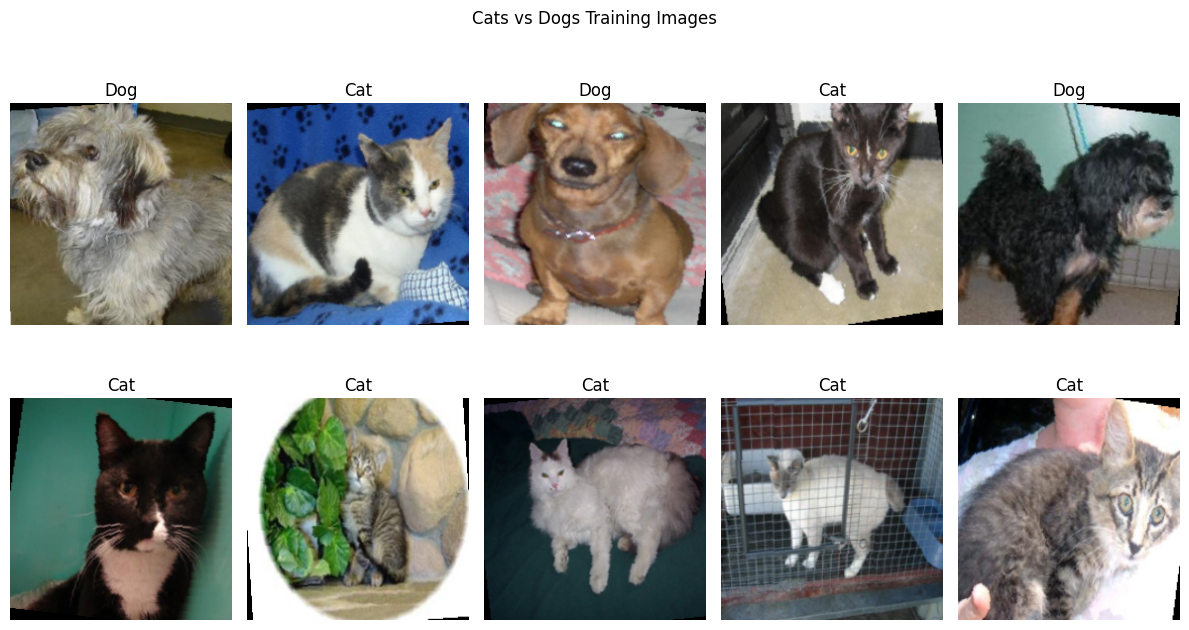


Loading pre-trained ResNet18...
Pre-trained ResNet18 loaded.
Pre-trained layers frozen.

Modified ResNet18:
Linear(in_features=512, out_features=2, bias=True)

Loss Function : CrossEntropyLoss
Optimizer     : Adam
Learning Rate : 0.001

STAGE 1: TRAINING NEW CLASSIFIER
Epoch [1/2] Loss: 0.1234 Accuracy: 95.29%
Epoch [2/2] Loss: 0.0880 Accuracy: 96.58%

Unfreezing ResNet18 layer4...
Layer4 and final classifier are now trainable.
Fine-tuning learning rate: 0.0001

STAGE 2: FINE-TUNING RESNET18
Epoch [1/5] Loss: 0.0777 Accuracy: 97.14%
Epoch [2/5] Loss: 0.0449 Accuracy: 98.36%
Epoch [3/5] Loss: 0.0320 Accuracy: 98.84%
Epoch [4/5] Loss: 0.0244 Accuracy: 99.19%
Epoch [5/5] Loss: 0.0212 Accuracy: 99.18%

EVALUATION RESULTS
Accuracy  : 98.56%
Precision : 98.56%
Recall    : 98.56%
F1 Score  : 98.56%


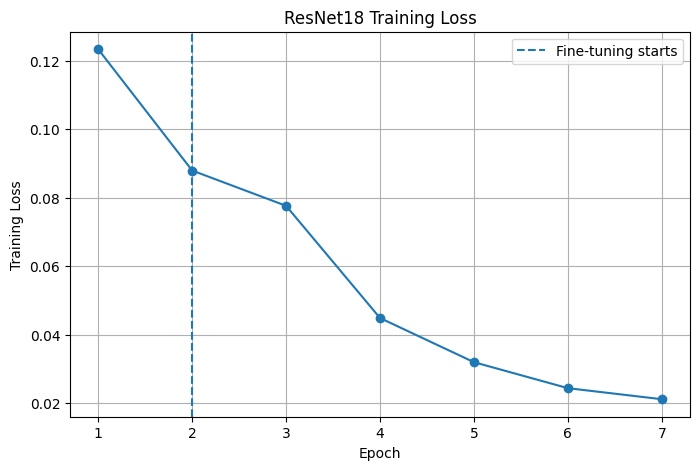

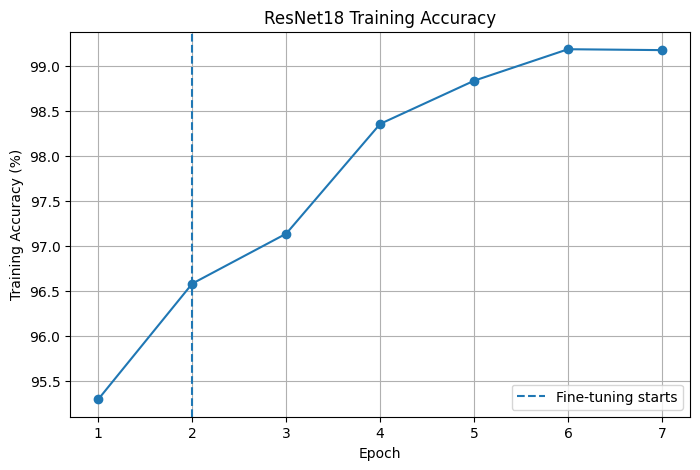

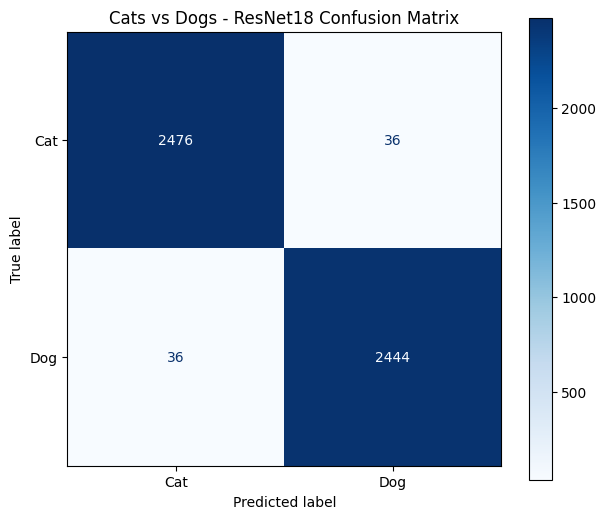

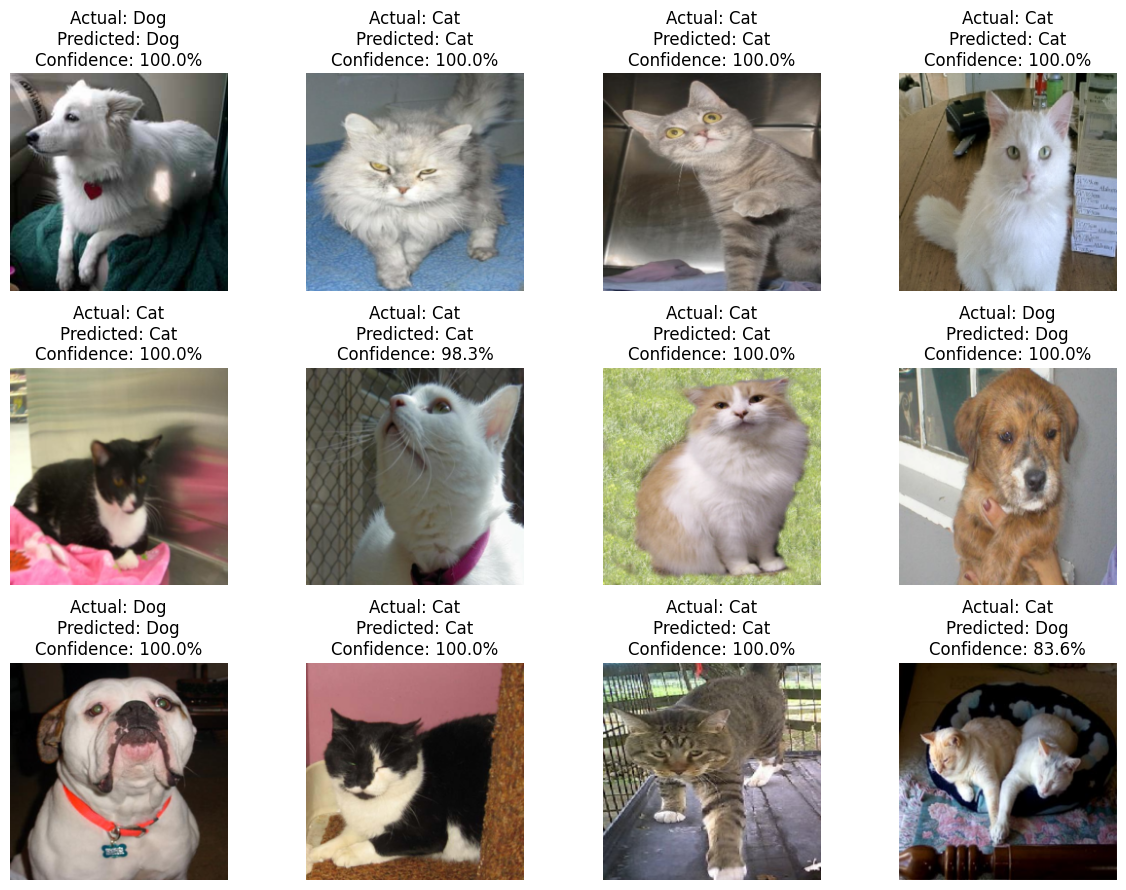


FINAL RESULTS
Test Accuracy : 98.56%
Precision     : 98.56%
Recall        : 98.56%
F1 Score      : 98.56%

CONCLUSION

The Cats vs Dogs dataset was successfully loaded and
preprocessed for transfer learning.

A ResNet18 model pre-trained on ImageNet was used as the
base CNN.

Initially, the pre-trained convolutional layers were frozen
and only the new final classification layer was trained.

In the second stage, the final ResNet block (layer4) and
the new classification layer were unfrozen and fine-tuned
using a smaller learning rate.

This demonstrates transfer learning because the model
reuses visual features learned from the large ImageNet
dataset instead of learning all features from the beginning.

The model was evaluated using Accuracy, Precision, Recall
and F1 Score.

Training loss and accuracy were visualized using graphs,
and a confusion matrix was used to analyze Cat and Dog
classification performance.

Actual and predicted images were also displayed to
visually inspect the 

In [6]:
# ============================================================
# LAB / EXPERIMENT 10
# TRANSFER LEARNING: FINE-TUNING A PRE-TRAINED CNN
# CATS VS DOGS CLASSIFICATION USING RESNET18
# ============================================================


# ============================================================
# 1. INSTALL AND IMPORT REQUIRED LIBRARIES
# ============================================================

!pip -q install kagglehub


import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

from torchvision.datasets import ImageFolder
from torchvision.models import resnet18, ResNet18_Weights

from torch.utils.data import DataLoader
from torch.utils.data import random_split
from torch.utils.data import Subset

from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import kagglehub


# ============================================================
# 2. SET RANDOM SEED AND DEVICE
# ============================================================

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ============================================================
# 3. DOWNLOAD CATS VS DOGS DATASET
# ============================================================

print("\nDownloading Cats vs Dogs dataset...")

dataset_download_path = kagglehub.dataset_download(
    "karakaggle/kaggle-cat-vs-dog-dataset"
)

print("Dataset downloaded successfully.")

print(
    "Dataset location:",
    dataset_download_path
)


# ============================================================
# 4. FIND CAT AND DOG FOLDERS
# ============================================================

dataset_path = None

for root, dirs, files in os.walk(
    dataset_download_path
):

    folder_names = [
        d.lower()
        for d in dirs
    ]

    if (
        "cat" in folder_names
        and
        "dog" in folder_names
    ):

        dataset_path = root

        break


if dataset_path is None:

    raise FileNotFoundError(
        "Cat and Dog folders were not found."
    )


print(
    "\nDataset path:",
    dataset_path
)

print(
    "Folders:",
    os.listdir(dataset_path)
)


# ============================================================
# 5. CHECK FOR VALID IMAGE FILES
# ============================================================

def check_image(path):

    try:

        with Image.open(path) as img:
            img.verify()

        return True

    except:

        return False


# ============================================================
# 6. DEFINE TRAINING TRANSFORMATIONS
# ============================================================

# ResNet18 expects ImageNet-style input.
# Images are resized to 224 x 224.

train_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    # Data augmentation
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        10
    ),

    transforms.RandomResizedCrop(
        224,
        scale=(0.8, 1.0)
    ),

    transforms.ToTensor(),

    # ImageNet normalization
    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


# ============================================================
# 7. DEFINE TEST / VALIDATION TRANSFORMATIONS
# ============================================================

test_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


# ============================================================
# 8. LOAD DATASET
# ============================================================

train_full_dataset = ImageFolder(
    root=dataset_path,

    transform=train_transform,

    is_valid_file=check_image
)


test_full_dataset = ImageFolder(
    root=dataset_path,

    transform=test_transform,

    is_valid_file=check_image
)


print(
    "\nTotal valid images:",
    len(train_full_dataset)
)

print(
    "Classes:",
    train_full_dataset.classes
)


# ============================================================
# 9. SPLIT DATASET INTO TRAINING AND TESTING
# ============================================================

total_size = len(
    train_full_dataset
)

train_size = int(
    0.8 * total_size
)

test_size = (
    total_size -
    train_size
)


# Use the same random indices
# for both datasets

generator = torch.Generator().manual_seed(42)

train_indices, test_indices = random_split(
    range(total_size),
    [train_size, test_size],
    generator=generator
)


# Create datasets using the indices

train_dataset = Subset(
    train_full_dataset,
    train_indices.indices
)

test_dataset = Subset(
    test_full_dataset,
    test_indices.indices
)


print(
    "\nTraining images:",
    len(train_dataset)
)

print(
    "Testing images:",
    len(test_dataset)
)


# ============================================================
# 10. CREATE DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


print("\nDataLoaders created successfully.")


# ============================================================
# 11. DISPLAY SAMPLE IMAGES
# ============================================================

images, labels = next(
    iter(train_loader)
)


# ImageNet normalization values
mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)


plt.figure(
    figsize=(12, 7)
)


for i in range(10):

    plt.subplot(
        2,
        5,
        i + 1
    )

    image = images[i]

    # Undo normalization
    image = image * std + mean

    image = torch.clamp(
        image,
        0,
        1
    )

    image = image.permute(
        1,
        2,
        0
    )

    plt.imshow(image)

    if labels[i].item() == 0:
        class_name = "Cat"
    else:
        class_name = "Dog"

    plt.title(class_name)

    plt.axis("off")


plt.suptitle(
    "Cats vs Dogs Training Images"
)

plt.tight_layout()

plt.show()


# ============================================================
# 12. LOAD PRE-TRAINED RESNET18
# ============================================================

print(
    "\nLoading pre-trained ResNet18..."
)


weights = ResNet18_Weights.DEFAULT

model = resnet18(
    weights=weights
)


print(
    "Pre-trained ResNet18 loaded."
)


# ============================================================
# 13. FREEZE PRE-TRAINED LAYERS
# ============================================================

# Initially freeze all layers

for param in model.parameters():

    param.requires_grad = False


print(
    "Pre-trained layers frozen."
)


# ============================================================
# 14. REPLACE FINAL CLASSIFICATION LAYER
# ============================================================

# ResNet18 originally predicts 1000 ImageNet classes.
# We replace the final layer with 2 outputs:
# Cat and Dog.

num_features = model.fc.in_features


model.fc = nn.Linear(
    num_features,
    2
)


# The new final layer should be trainable

for param in model.fc.parameters():

    param.requires_grad = True


# Move model to device

model = model.to(device)


print(
    "\nModified ResNet18:"
)

print(model.fc)


# ============================================================
# 15. DEFINE LOSS FUNCTION AND OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()


# Initially train only the new final layer

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)


print(
    "\nLoss Function : CrossEntropyLoss"
)

print(
    "Optimizer     : Adam"
)

print(
    "Learning Rate : 0.001"
)


# ============================================================
# 16. FIRST TRAINING STAGE
# TRAIN ONLY THE NEW CLASSIFIER
# ============================================================

head_epochs = 2

head_losses = []

head_accuracies = []


print(
    "\n============================================================"
)

print(
    "STAGE 1: TRAINING NEW CLASSIFIER"
)

print(
    "============================================================"
)


for epoch in range(
    head_epochs
):

    model.train()

    running_loss = 0.0

    correct = 0

    total = 0


    for images, labels in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        optimizer.zero_grad()


        outputs = model(
            images
        )


        loss = criterion(
            outputs,
            labels
        )


        loss.backward()


        optimizer.step()


        running_loss += loss.item()


        _, predicted = torch.max(
            outputs,
            1
        )


        total += labels.size(0)


        correct += (
            predicted == labels
        ).sum().item()


    epoch_loss = (
        running_loss /
        len(train_loader)
    )


    epoch_accuracy = (
        100 * correct /
        total
    )


    head_losses.append(
        epoch_loss
    )

    head_accuracies.append(
        epoch_accuracy
    )


    print(
        f"Epoch [{epoch+1}/{head_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )


# ============================================================
# 17. UNFREEZE LAST RESNET BLOCK
# ============================================================

print(
    "\nUnfreezing ResNet18 layer4..."
)


# Fine-tune the last convolutional block

for param in model.layer4.parameters():

    param.requires_grad = True


# Keep final classifier trainable

for param in model.fc.parameters():

    param.requires_grad = True


# Use a smaller learning rate
# for fine-tuning

optimizer = optim.Adam(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=0.0001
)


print(
    "Layer4 and final classifier are now trainable."
)

print(
    "Fine-tuning learning rate: 0.0001"
)


# ============================================================
# 18. FINE-TUNE RESNET18
# ============================================================

fine_tune_epochs = 5

fine_losses = []

fine_accuracies = []


print(
    "\n============================================================"
)

print(
    "STAGE 2: FINE-TUNING RESNET18"
)

print(
    "============================================================"
)


for epoch in range(
    fine_tune_epochs
):

    model.train()

    running_loss = 0.0

    correct = 0

    total = 0


    for images, labels in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        optimizer.zero_grad()


        outputs = model(
            images
        )


        loss = criterion(
            outputs,
            labels
        )


        loss.backward()


        optimizer.step()


        running_loss += loss.item()


        _, predicted = torch.max(
            outputs,
            1
        )


        total += labels.size(0)


        correct += (
            predicted == labels
        ).sum().item()


    epoch_loss = (
        running_loss /
        len(train_loader)
    )


    epoch_accuracy = (
        100 * correct /
        total
    )


    fine_losses.append(
        epoch_loss
    )

    fine_accuracies.append(
        epoch_accuracy
    )


    print(
        f"Epoch [{epoch+1}/{fine_tune_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )


# ============================================================
# 19. COMBINE TRAINING HISTORY
# ============================================================

all_losses = (
    head_losses +
    fine_losses
)

all_accuracies = (
    head_accuracies +
    fine_accuracies
)

total_epochs = (
    head_epochs +
    fine_tune_epochs
)


# ============================================================
# 20. EVALUATE MODEL
# ============================================================

model.eval()

y_true = []

y_pred = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )


        outputs = model(
            images
        )


        _, predicted = torch.max(
            outputs,
            1
        )


        y_true.extend(
            labels.numpy()
        )


        y_pred.extend(
            predicted.cpu().numpy()
        )


# ============================================================
# 21. CALCULATE EVALUATION METRICS
# ============================================================

accuracy = accuracy_score(
    y_true,
    y_pred
)


precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)


recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)


f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)


# ============================================================
# 22. DISPLAY EVALUATION RESULTS
# ============================================================

print(
    "\n============================================================"
)

print(
    "EVALUATION RESULTS"
)

print(
    "============================================================"
)


print(
    f"Accuracy  : {accuracy * 100:.2f}%"
)


print(
    f"Precision : {precision * 100:.2f}%"
)


print(
    f"Recall    : {recall * 100:.2f}%"
)


print(
    f"F1 Score  : {f1 * 100:.2f}%"
)


# ============================================================
# 23. PLOT TRAINING LOSS
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    range(
        1,
        total_epochs + 1
    ),
    all_losses,
    marker="o"
)


# Show where fine-tuning starts

plt.axvline(
    x=head_epochs,
    linestyle="--",
    label="Fine-tuning starts"
)


plt.xlabel("Epoch")

plt.ylabel("Training Loss")

plt.title(
    "ResNet18 Training Loss"
)

plt.legend()

plt.grid()

plt.show()


# ============================================================
# 24. PLOT TRAINING ACCURACY
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    range(
        1,
        total_epochs + 1
    ),
    all_accuracies,
    marker="o"
)


plt.axvline(
    x=head_epochs,
    linestyle="--",
    label="Fine-tuning starts"
)


plt.xlabel("Epoch")

plt.ylabel(
    "Training Accuracy (%)"
)

plt.title(
    "ResNet18 Training Accuracy"
)

plt.legend()

plt.grid()

plt.show()


# ============================================================
# 25. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)


fig, ax = plt.subplots(
    figsize=(7, 6)
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Cat",
        "Dog"
    ]
)


disp.plot(
    ax=ax,
    cmap="Blues"
)


plt.title(
    "Cats vs Dogs - ResNet18 Confusion Matrix"
)

plt.show()


# ============================================================
# 26. DISPLAY ACTUAL VS PREDICTED IMAGES
# ============================================================

images, labels = next(
    iter(test_loader)
)


images_device = images.to(
    device
)


with torch.no_grad():

    outputs = model(
        images_device
    )


    probabilities = torch.softmax(
        outputs,
        dim=1
    )


    _, predictions = torch.max(
        outputs,
        1
    )


plt.figure(
    figsize=(12, 9)
)


for i in range(12):

    plt.subplot(
        3,
        4,
        i + 1
    )


    image = images[i]


    # Undo ImageNet normalization

    image = image * std + mean


    image = torch.clamp(
        image,
        0,
        1
    )


    image = image.permute(
        1,
        2,
        0
    )


    plt.imshow(image)


    if labels[i].item() == 0:

        actual = "Cat"

    else:

        actual = "Dog"


    if predictions[i].item() == 0:

        predicted = "Cat"

    else:

        predicted = "Dog"


    confidence = (
        probabilities[i][
            predictions[i]
        ].item()
        * 100
    )


    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.1f}%"
    )


    plt.axis("off")


plt.tight_layout()

plt.show()


# ============================================================
# 27. FINAL RESULTS
# ============================================================

print(
    "\n============================================================"
)

print(
    "FINAL RESULTS"
)

print(
    "============================================================"
)


print(
    f"Test Accuracy : {accuracy * 100:.2f}%"
)


print(
    f"Precision     : {precision * 100:.2f}%"
)


print(
    f"Recall        : {recall * 100:.2f}%"
)


print(
    f"F1 Score      : {f1 * 100:.2f}%"
)


# ============================================================
# 28. CONCLUSION
# ============================================================

print(
    "\n============================================================"
)

print(
    "CONCLUSION"
)

print(
    "============================================================"
)


print("""
The Cats vs Dogs dataset was successfully loaded and
preprocessed for transfer learning.

A ResNet18 model pre-trained on ImageNet was used as the
base CNN.

Initially, the pre-trained convolutional layers were frozen
and only the new final classification layer was trained.

In the second stage, the final ResNet block (layer4) and
the new classification layer were unfrozen and fine-tuned
using a smaller learning rate.

This demonstrates transfer learning because the model
reuses visual features learned from the large ImageNet
dataset instead of learning all features from the beginning.

The model was evaluated using Accuracy, Precision, Recall
and F1 Score.

Training loss and accuracy were visualized using graphs,
and a confusion matrix was used to analyze Cat and Dog
classification performance.

Actual and predicted images were also displayed to
visually inspect the predictions.

Overall, transfer learning with ResNet18 provides a
practical approach for image classification because
pre-trained visual features can be adapted to a new
two-class problem with comparatively limited training.
""")